# Portfolio Replica — Failed Attempt Comparison

This notebook is intentionally kept as a separate exploratory attempt. It documents a set of experiments that were useful for testing ideas, but was not selected as the final approach.

In particular the notebook contains:
* [the more basic linear regression attempt to the problem](#Elastic-net)
* [the pooling](#Pooling)
* [an introduction to the Soft Markov Switching Elastic Net](#The-Soft-Markov-Switching-Elastic-Net)
* [the more basic Kalman Filter replication approach](#Kalman-Filter-Replication)




In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from scipy import stats
from itertools import product
from arch import arch_model
from scipy.stats import norm, chi2
from sklearn.cluster import KMeans
from scipy.stats import t as student_t
from scipy.optimize import minimize
import warnings
warnings.filterwarnings("ignore")

## Data Loading & Target Construction

In [2]:
DATA_PATH = r'/Users/pierpa/Documents/FINTECH/BusinessCase3/Dataset3_PortfolioReplicaStrategy.xlsx'
raw = pd.read_excel(DATA_PATH)

INDEX_COLS   = ["MXWO", "MXWD", "LEGATRUU", "HFRXGL"]
FUTURES_COLS = ["RX1", "TY1", "GC1", "CO1", "ES1", "VG1", "NQ1", "LLL1", "TP1", "DU1", "TU2"]

data = raw.copy().rename(columns={"Ticker": "Date"})
data["Date"] = pd.to_datetime(data["Date"])
data = data.set_index("Date").apply(pd.to_numeric, errors="coerce").sort_index()
print(f"Loaded: {data.shape[0]} weeks x {data.shape[1]} instruments")
print(f"Date range: {data.index[0].date()} — {data.index[-1].date()}")

returns     = data.pct_change().dropna()
index_ret   = data[INDEX_COLS].pct_change().dropna()
futures_ret = returns[FUTURES_COLS]

ANNUAL_FACTOR   = 52
sharpe_ratios   = (index_ret.mean() * ANNUAL_FACTOR) / (index_ret.std() * np.sqrt(ANNUAL_FACTOR))
MONSTER_WEIGHTS = sharpe_ratios / sharpe_ratios.sum()
print("Monster Index weights:")
print(MONSTER_WEIGHTS.round(4))

target = sum(index_ret[k] * w for k, w in MONSTER_WEIGHTS.items()).dropna()
target.name = "Monster_Index"

common_idx  = futures_ret.index.intersection(target.index)
futures_ret = futures_ret.loc[common_idx]
target      = target.loc[common_idx]

# Remove stale futures (>100 zero-diff weeks)
futures_const = [c for c in futures_ret.columns if (futures_ret[c].diff()==0).sum()>100]
print("Removed (stale):", futures_const)
futures_ret = futures_ret.drop(columns=futures_const)

X = futures_ret.copy()
y = target.copy()

X_values    = X.values
y_values    = y.values
dates_array = X.index.to_numpy()
print(f"OOS array shape: X={X_values.shape}, y={y_values.shape}")

Loaded: 705 weeks x 15 instruments
Date range: 2007-10-23 — 2021-04-20
Monster Index weights:
MXWO        0.2439
MXWD        0.2242
LEGATRUU    0.4564
HFRXGL      0.0754
dtype: float64
Removed (stale): ['LLL1']
OOS array shape: X=(704, 10), y=(704,)


# OLS allocation

In this section, we explore several alternative configurations built around the original OLS allocation framework. 

## Initial OLS-based approach

Our initial OLS-based approach produced reasonably good results and was able to replicate the portfolio behaviour decently. 

Moreover, during specific market periods the portfolio gross exposure reached very high values (up to approximately 5), revealing highly leveraged allocations caused by strong compensation between positive and negative portfolio weights. Moreover, the resulting allocations exhibited relatively high turnover, leading to unstable portfolio dynamics and potentially unrealistic implementation costs.

These observations motivated a series of exploratory attempts aimed at improving the robustness, stability, and practical interpretability of the allocation process, while preserving as much as possible the predictive capability of the original model.

To address these issues, we experimented with:

- exponentially weighted approaches, assigning larger importance to more recent observations,
- long-only allocations
- different rebalances frequency

The long-only setting was introduced after observing that the extreme gross exposure values were mainly driven by offsetting long and short positions. By constraining the portfolio to non-negative weights, we aimed to obtain more stable and realistic allocations.

All the variables and functions defined below are exactly the same as in the main notebook; for this reason, comments are kept as simple as possible.

### Hyperparameter Grid & VaR Functions

We define the hyperparameter grid below.


In [3]:
alphas = [0.0001, 0.001, 0.01, 0.1]
l1_ratios = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
rolling_windows = [104, 208]

var_confidence    = 0.01
var_horizon       = 4
max_var_threshold = 0.20
TURNOVER_THRESHOLD = 0.03
TRANSACTION_COST   = 0.0004

VIF_THRESHOLD    = 10.0
VIF_MIN_FEATURES = 2

We define the substantial VaR used for the Max 1M VaR(99%) constraint in the elastic net models


In [4]:
def var_student_t(returns, confidence=0.01, horizon=4):
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    df, loc, scale = stats.t.fit(returns)
    q = stats.t.ppf(confidence, df, loc=loc, scale=scale)
    return -q * np.sqrt(horizon)


def var_garch_t(returns, confidence=0.01, horizon=4, n_sim=5000):
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1, dist='t').fit(disp='off', show_warning=False)
    omega = res.params['omega']; ga = res.params['alpha[1]']
    beta  = res.params['beta[1]']; nu = res.params['nu']
    sigma0 = res.conditional_volatility[-1]
    z_matrix = stats.t.rvs(df=nu, size=(n_sim, horizon))
    sigma = np.full(n_sim, sigma0); cum_path = np.zeros(n_sim)
    for h in range(horizon):
        eps = sigma * z_matrix[:, h]; cum_path += eps / 100
        sigma = np.sqrt(np.maximum(omega + ga * eps**2 + beta * sigma**2, 1e-8))
    return -np.percentile(cum_path, confidence * 100)


def var_filtered_bootstrap(returns, confidence=0.01, horizon=4, n_sim=5000, random_state=42):
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1, dist='normal').fit(disp='off', show_warning=False)
    std_resid = res.std_resid; std_resid = std_resid[np.isfinite(std_resid)]
    if std_resid.size == 0: raise ValueError("GARCH produced no valid residuals.")
    std_resid = std_resid - std_resid.mean()
    rs = std_resid.std()
    if rs > 1e-10: std_resid = std_resid / rs
    omega = res.params['omega']; ga = res.params['alpha[1]']
    beta  = res.params['beta[1]']; sigma0 = res.conditional_volatility[-1]
    rng = np.random.default_rng(random_state)
    idx = rng.integers(0, len(std_resid), size=(n_sim, horizon))
    z_matrix = std_resid[idx]
    sigma = np.full(n_sim, sigma0); cum_path = np.zeros(n_sim)
    for h in range(horizon):
        eps = sigma * z_matrix[:, h]; cum_path += eps / 100
        sigma = np.sqrt(np.maximum(omega + ga * eps**2 + beta * sigma**2, 1e-8))
    return -np.percentile(cum_path, confidence * 100)

### Elastic Net feature selection using VIF 

We define here the functions used in the elastic net for the selection of features with VIF


In [5]:
def compute_vif(X_window):
    n, p = X_window.shape
    vif  = np.full(p, np.nan)
    for j in range(p):
        X_j = X_window[:, j]; X_rest = np.delete(X_window, j, axis=1)
        X_rest_int = np.column_stack([np.ones(n), X_rest])
        try:
            coef, *_ = np.linalg.lstsq(X_rest_int, X_j, rcond=None)
            y_hat = X_rest_int @ coef
            ss_res = np.sum((X_j - y_hat)**2); ss_tot = np.sum((X_j - X_j.mean())**2)
            if ss_tot < 1e-12: vif[j] = np.nan
            else:
                r2 = np.clip(1.0 - ss_res / ss_tot, 0.0, 1.0 - 1e-9)
                vif[j] = 1.0 / (1.0 - r2)
        except Exception: vif[j] = np.nan
    return vif


def select_features_by_vif(X_window, threshold=VIF_THRESHOLD, min_features=VIF_MIN_FEATURES):
    n, p = X_window.shape
    if n < p + 2: return np.arange(p)
    scaler = StandardScaler()
    X_scaled = np.nan_to_num(scaler.fit_transform(X_window))
    remaining = list(range(p))
    while len(remaining) > min_features:
        X_sub = X_scaled[:, remaining]; vif = compute_vif(X_sub)
        vif_f = np.where(np.isnan(vif), np.inf, vif)
        if vif_f.max() <= threshold: break
        remaining.pop(int(np.argmax(vif_f)))
    return np.array(remaining, dtype=int)

### Sample Weight Functions

To account for time-varying market dynamics, observations in the training
window are assigned exponential decay weights. We define below the function
that computes these weights based on an adaptive half-life.


In [6]:
# ── Adaptive parameters ──────────────────────────────────────────────────────
USE_ADAPTIVE_REGIME  = True
ADAPTIVE_HALF_LIVES  = [4, 26, 52]   # fast / medium / slow decay
ADAPTIVE_ALPHA       = 1.0
HALF_LIFE_MIN        = 4
HALF_LIFE_MAX        = 78

In [7]:
# ── Adaptive half-life ────────────────────────────────────────────────────────
def compute_adaptive_regime_weights(y_train):
    """
    Compute an adaptive half-life by measuring mean absolute return activity
    over three nested windows (short ~T/6, medium ~T/2, full ~T) and
    taking their activity-weighted average of ADAPTIVE_HALF_LIVES.

    Each window's weight is proportional to its activity (mean |return|)
    raised to ADAPTIVE_ALPHA: windows with higher activity pull the
    half-life toward ADAPTIVE_HALF_LIVES[0] (faster decay), windows
    with lower activity pull it toward ADAPTIVE_HALF_LIVES[2] (slower decay).
    The result is clipped to [HALF_LIFE_MIN, HALF_LIFE_MAX].

    Returns
    -------
    half_life : int
    regime_probs : ndarray (3,)
        Normalised activity weights for the three windows.
    """
    T             = len(y_train)
    fractions     = [1/6, 1/2, 1.0]
    windows       = [max(4, int(T * f)) for f in fractions]
    activity      = np.array([np.mean(np.abs(y_train[-w:])) for w in windows])
    concentration = activity ** ADAPTIVE_ALPHA
    regime_probs  = concentration / (concentration.sum() + 1e-8)
    half_life     = int(np.clip(
        np.dot(regime_probs, ADAPTIVE_HALF_LIVES),
        HALF_LIFE_MIN, HALF_LIFE_MAX
    ))
    return half_life, regime_probs


# ── Sample weights (adaptive exponential decay) ──────────────────────────────
def compute_sample_weights(y_train):
    """
    Computes exponential decay sample weights using an adaptive half-life.
    The half-life is derived from recent return activity: higher recent
    activity produces a shorter half-life (more weight on recent obs),
    lower activity produces a longer one.

    Returns
    -------
    time_weights : ndarray (T,), normalised to sum to 1.
    """
    T = len(y_train)
    half_life, _ = compute_adaptive_regime_weights(y_train)
    decay        = 0.5 ** (1.0 / half_life)
    time_weights = np.array([decay ** (T - 1 - i) for i in range(T)])
    return  time_weights /  time_weights.sum()



### evaluate_config_with_tss

We define here all the functions for the fitting of the elastic net

In [8]:
# ── Storage for Elastic Net rolling loop ─────────────────────────────────────
y_pred_Enet = []
y_test_Enet = []

weights_Enet         = []
gross_exposure_Enet  = []
tracking_error_Enet  = []

var_Enet             = []
scaling_factors_Enet = []

best_alpha_history    = []
best_l1_ratio_history = []
best_window_history   = []
regime_history        = []

dates_Enet = []

In [9]:
def fit_elastic_net_scaled(
    X_train,
    y_train,
    alpha,
    l1_ratio,
    sample_weight=None,
    positive=False
):
    # =========================
    # Normalize X
    # =========================
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_train)
    # =========================
    # Normalize y
    # =========================
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(
        y_train.reshape(-1, 1)
    ).ravel()
    # =========================
    # Train in normalized space
    # =========================
    model = ElasticNet(
        alpha=alpha,
        l1_ratio=l1_ratio,
        fit_intercept=False,
        max_iter=10000,
        tol=1e-4,
        positive=positive,
        random_state=42
    )
    model.fit(
        X_scaled,
        y_scaled,
        sample_weight=sample_weight
    )
    # =========================
    # Rescale coefficients
    # =========================
    beta_original = (
        model.coef_
        * scaler_y.scale_[0]
        / scaler_X.scale_
    )
    # =========================
    # Recover intercept
    # =========================
    intercept_original = (
        scaler_y.mean_[0]
        - np.sum(scaler_X.mean_ * beta_original)
    )
    return beta_original, intercept_original, model
    
def evaluate_config_with_tss(X_train_full, y_train_full, alpha, l1_ratio,
                              n_splits=3, positive=False, use_ewm=False):
    tscv = TimeSeriesSplit(n_splits=n_splits)
    rep_cv, tgt_cv = [], []
    for train_idx, val_idx in tscv.split(X_train_full):
        X_tr, y_tr = X_train_full[train_idx], y_train_full[train_idx]
        X_val, y_val = X_train_full[val_idx], y_train_full[val_idx]
        sw = compute_sample_weights(y_tr) if use_ewm else None
        w, intercept, _ = fit_elastic_net_scaled(X_tr, y_tr, alpha, l1_ratio, sample_weight=sw, positive=positive)
        rep_cv.extend(X_val @ w + intercept); tgt_cv.extend(y_val)
    rep_cv = np.asarray(rep_cv); tgt_cv = np.asarray(tgt_cv)
    te_vol = np.std(rep_cv - tgt_cv) * np.sqrt(52)
    if te_vol == 0: return -np.inf
    return (np.mean(rep_cv) * 52 - np.mean(tgt_cv) * 52) / te_vol

### Performance Metric Helper

We define here the function to print the metrics of our models

In [10]:
def compute_metrics(y_pred, y_test, weights_list):
    te   = y_pred - y_test
    tev  = te.std() * np.sqrt(52)
    ir   = (y_pred.mean() * 52 - y_test.mean() * 52) / tev if tev > 0 else np.nan
    corr = y_pred.corr(y_test)
    cum_r = (1 + y_pred).cumprod()
    cum_t = (1 + y_test).cumprod()
    mdd_r = (1 - cum_r / cum_r.cummax()).max()
    mdd_t = (1 - cum_t / cum_t.cummax()).max()
    sharpe_r = (y_pred.mean() * 52) / (y_pred.std() * np.sqrt(52))
    sharpe_t = (y_test.mean() * 52) / (y_test.std() * np.sqrt(52))
    d_w  = np.diff(np.asarray(weights_list), axis=0)
    to   = np.sum(np.abs(d_w), axis=1) / 2
    return dict(
        IR=ir, TEV=tev, Corr=corr,
        Sharpe_R=sharpe_r, Sharpe_T=sharpe_t,
        Ret_R=y_pred.mean()*52, Ret_T=y_test.mean()*52,
        Vol_R=y_pred.std()*np.sqrt(52),
        MaxDD_R=mdd_r, MaxDD_T=mdd_t,
        AvgTO=to.mean()*52,
        MSE=np.mean(te**2)
    )

### Configuration Definitions

We define below the four configurations we tested:
- **OLS R1**: plain OLS, weekly rebalancing, no exponential weighting, long/short
- **OLS R4**: plain OLS, monthly rebalancing (every 4 weeks), no exponential weighting, long/short
- **EWM R4**: OLS with exponential sample weighting, monthly rebalancing, long/short
- **OLS R4 LO**: plain OLS, monthly rebalancing, long-only constraint

These configurations were selected sequentially: each addition was retained only if it
produced a meaningful improvement in replication quality. Following an Occam's razor
principle, complexity was added only when justified by performance gains. As an example,
exponential sample weighting (EWM R4) did not yield sufficient improvement over plain
OLS R4 and was therefore discarded in the final design.

In [11]:
CONFIGS = [
    dict(label="OLS R1",         REBAL_FREQ=1,  USE_EWM=False, LONG_ONLY=False),
    dict(label="OLS R4",         REBAL_FREQ=4, USE_EWM=False, LONG_ONLY=False),
    dict(label="EWM R4", REBAL_FREQ=4, USE_EWM=True,  LONG_ONLY=False),
    dict(label="OLS R4 LO",      REBAL_FREQ=4, USE_EWM=False,  LONG_ONLY=True),
]

N_CONFIGS = len(CONFIGS)

# Storage for all results (populated in the loop below)
all_results = []

USE_TURNOVER_GATE  = True
USE_VAR_CONSTRAINT = True

### Main Comparison Loop

For each configuration: run the rolling Elastic Net loop, compute metrics, plot individual dashboard (portfolio vs clone + GE), then show accumulated comparison.


  CONFIG 1/4 : OLS R1
  Rebal=1w  EWM=False  LongOnly=False

  IR=-0.081  TEV=3.80%  Corr=0.862  Sharpe_R=0.88  MaxDD_R=12.7%  AvgTO=10.06  AvgGE=1.47


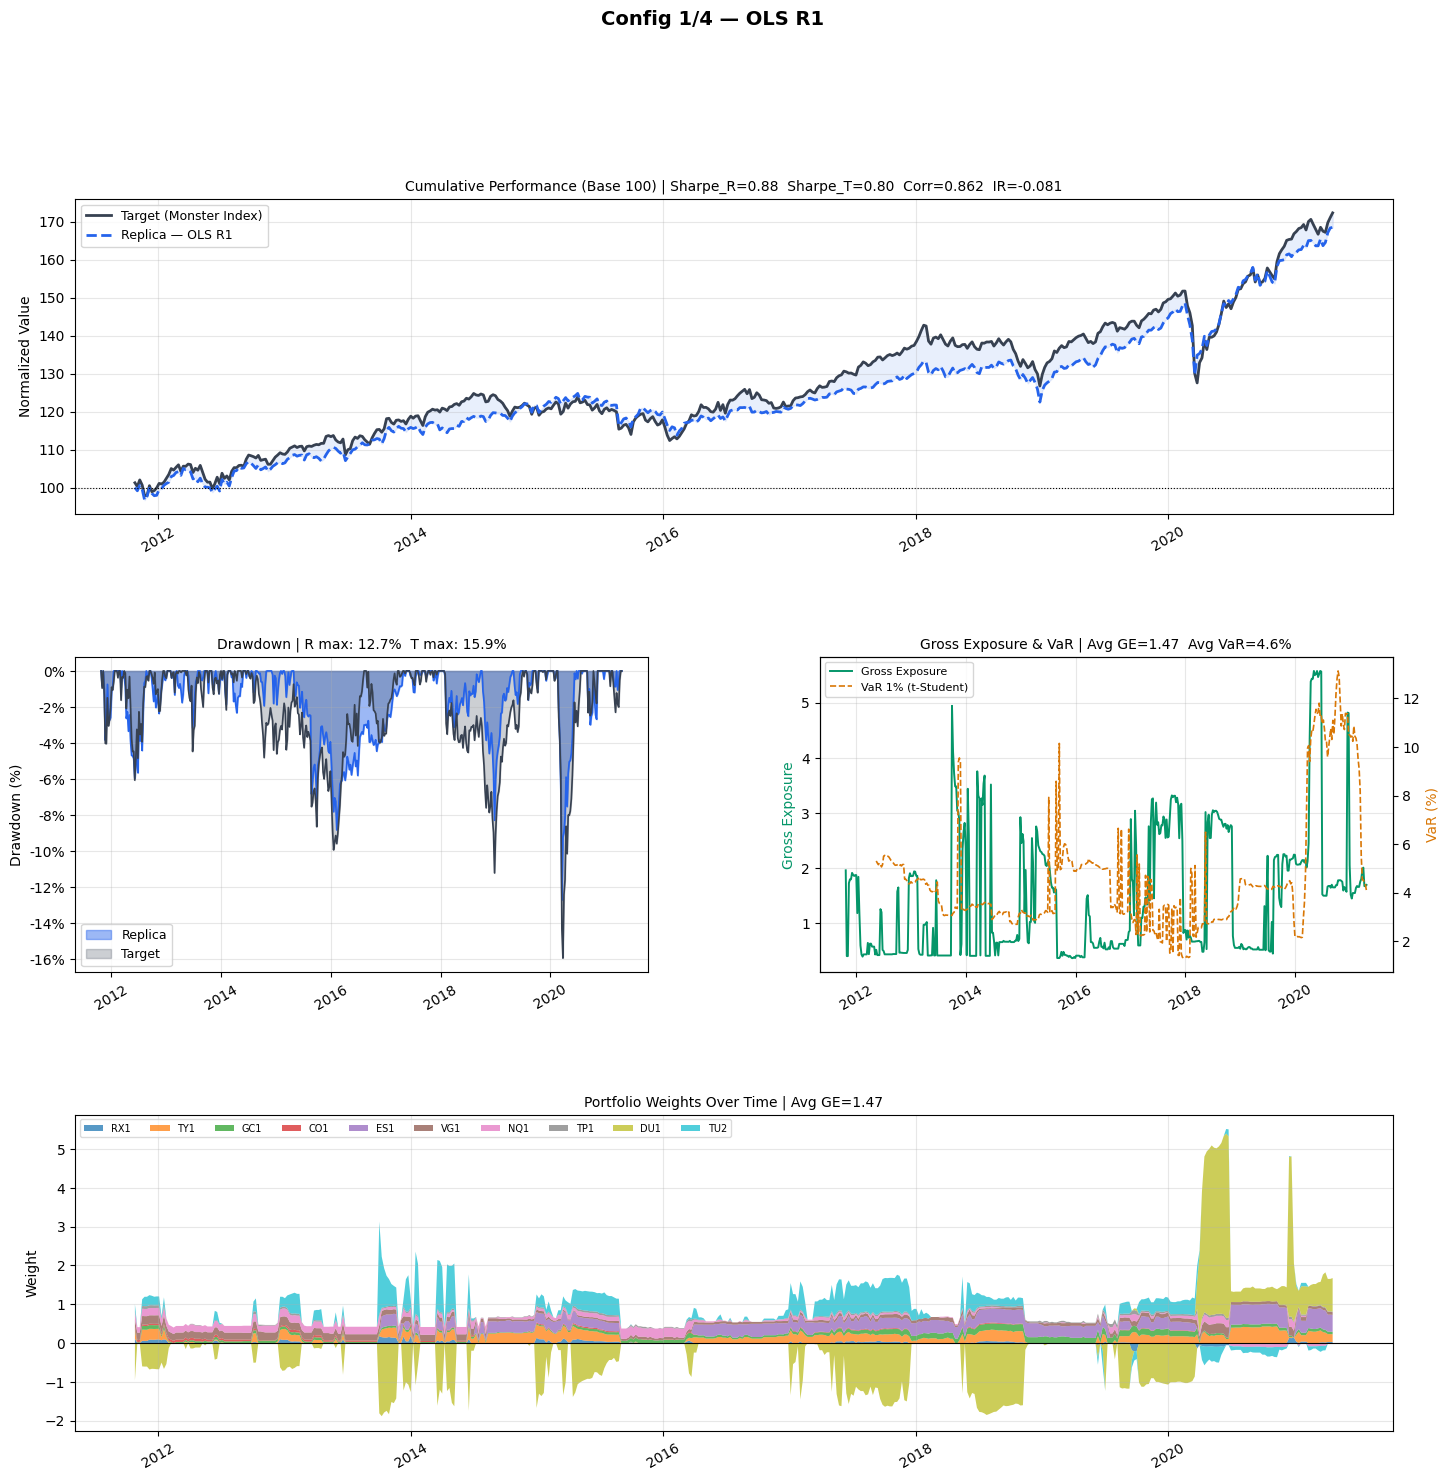

  Saved: dashboard_cfg1_OLS_R1.png


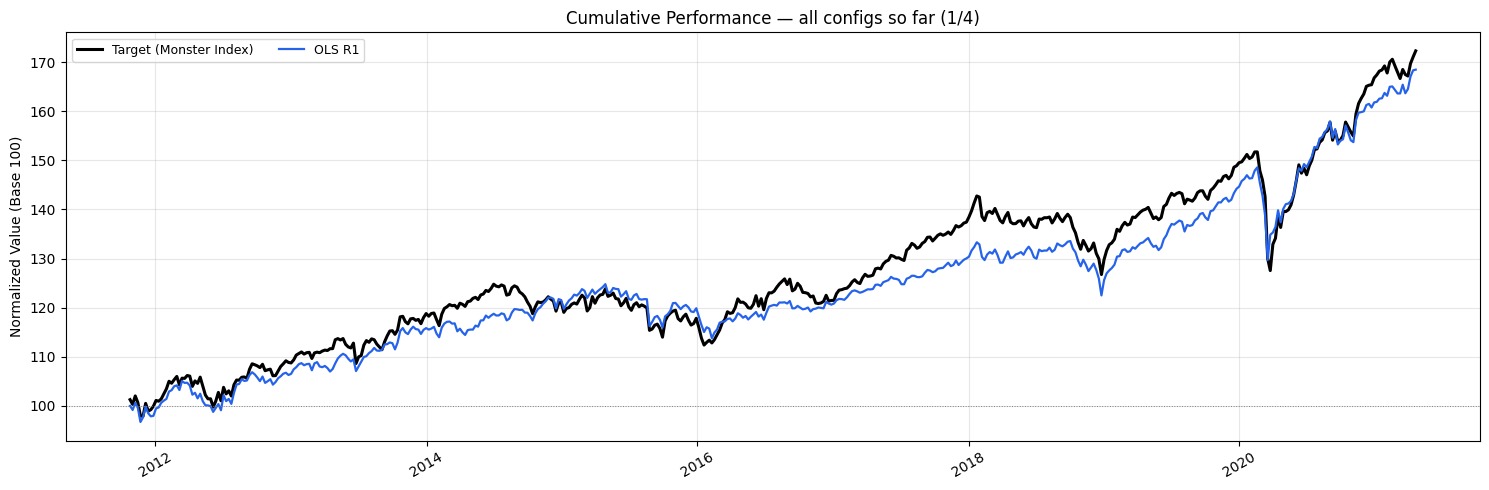


  Accumulated metrics (1/4):


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
OLS R1,-0.081,3.8,0.862,0.88,5.68,6.47,12.7,1.47,10.06,2.77e-05



  CONFIG 2/4 : OLS R4
  Rebal=4w  EWM=False  LongOnly=False

  IR=0.036  TEV=3.64%  Corr=0.874  Sharpe_R=0.94  MaxDD_R=13.0%  AvgTO=4.51  AvgGE=1.48


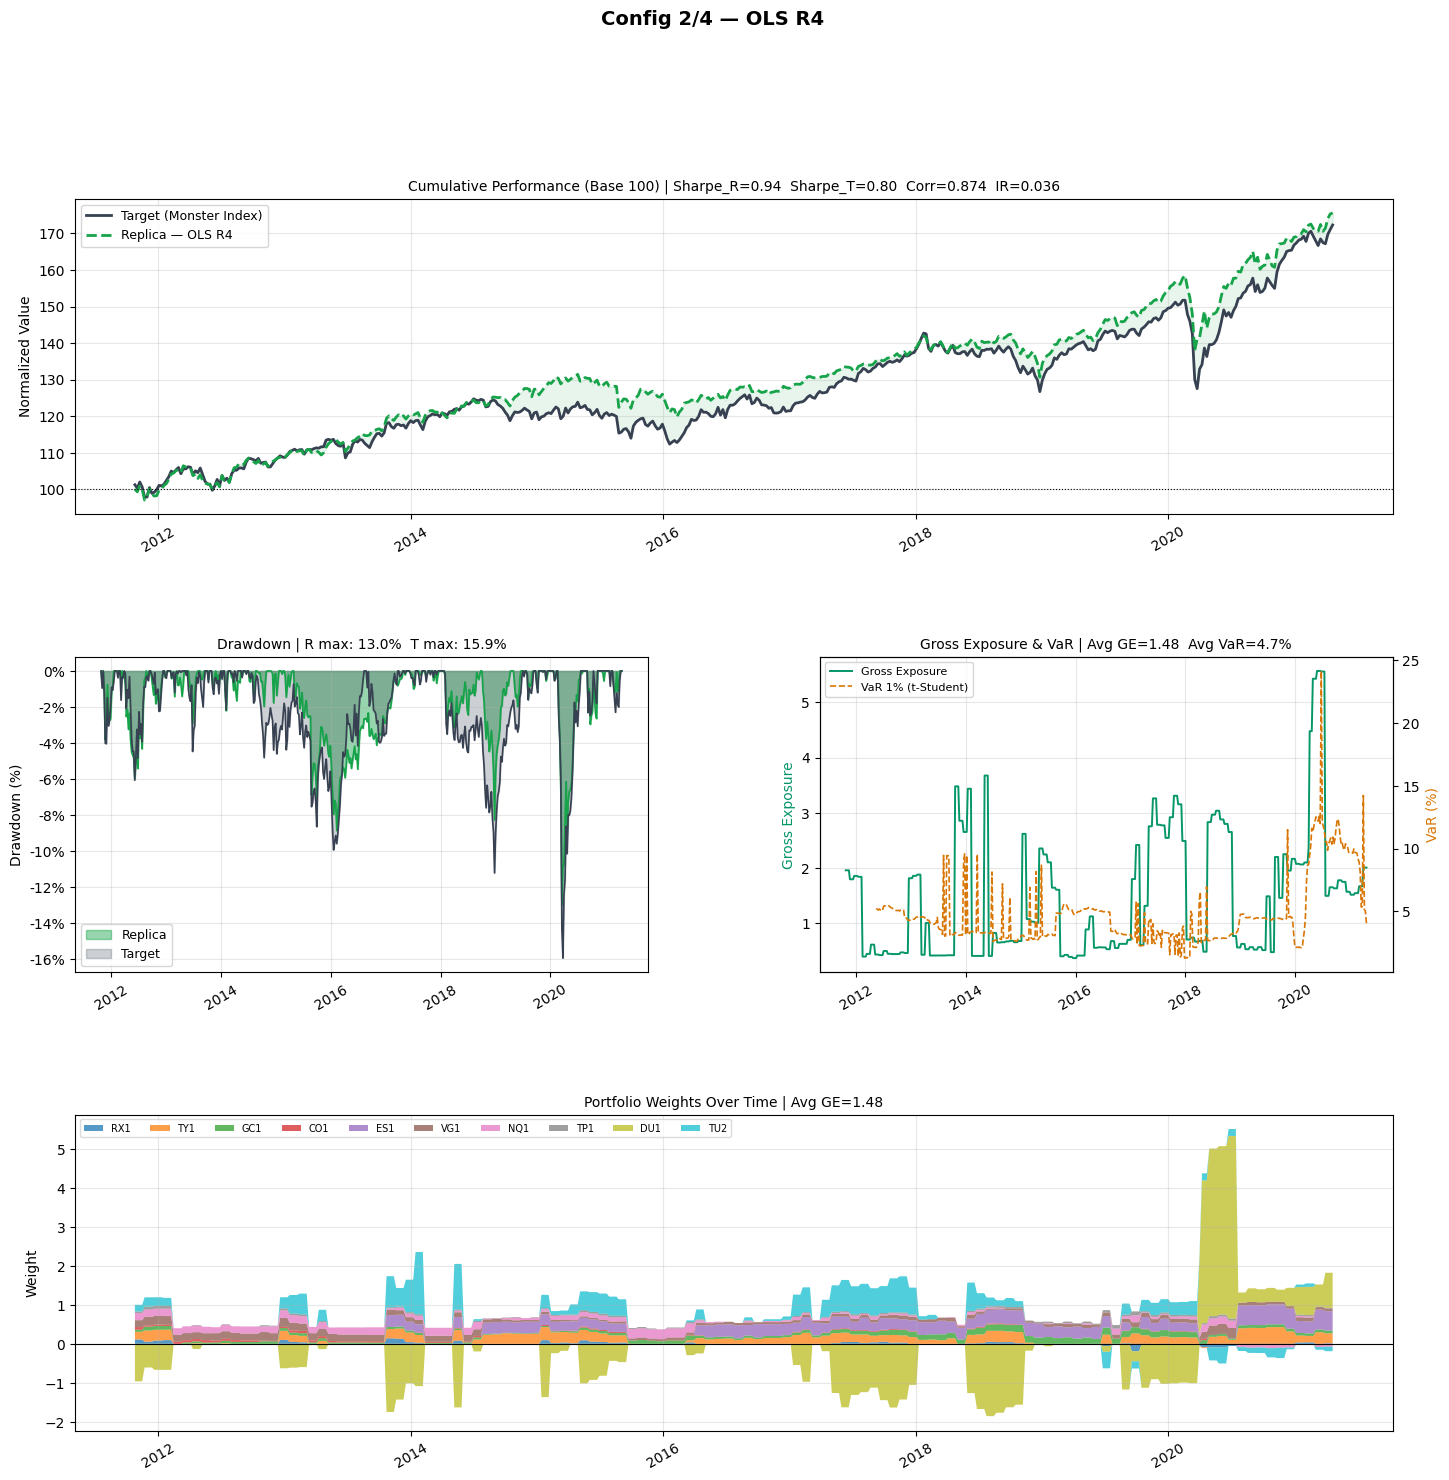

  Saved: dashboard_cfg2_OLS_R4.png


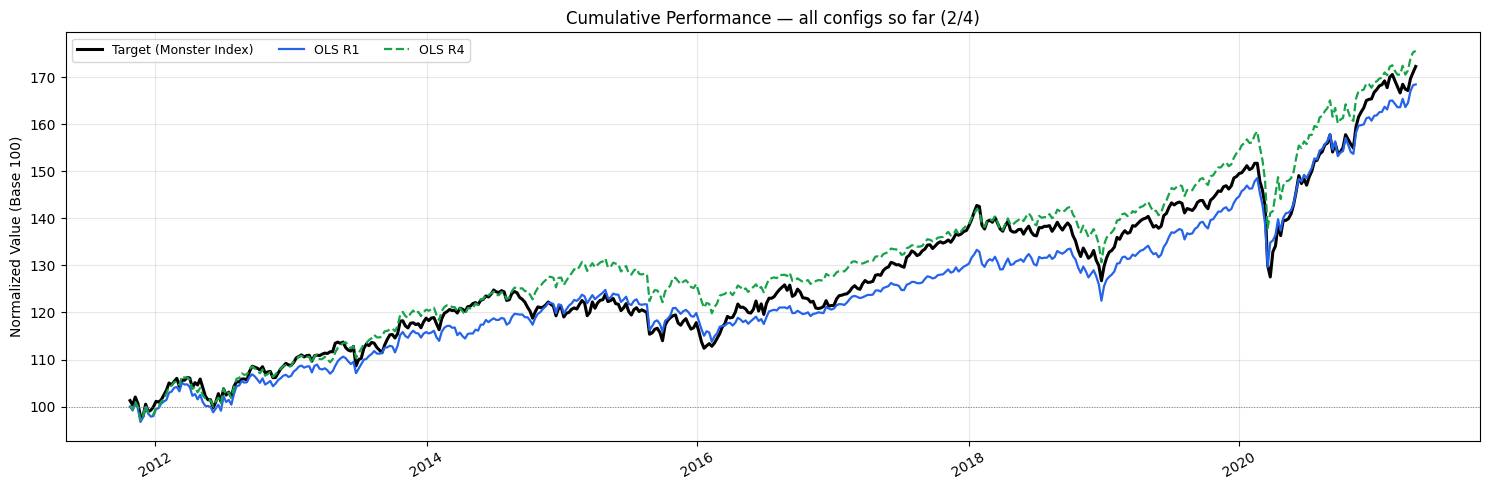


  Accumulated metrics (2/4):


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
OLS R1,-0.081,3.80,0.862,0.88,5.68,6.47,12.7,1.47,10.06,2.77e-05
OLS R4,0.036,3.64,0.874,0.94,6.12,6.54,13.0,1.48,4.51,2.55e-05



  CONFIG 3/4 : EWM R4
  Rebal=4w  EWM=True  LongOnly=False

  IR=0.126  TEV=3.79%  Corr=0.863  Sharpe_R=0.99  MaxDD_R=11.9%  AvgTO=5.36  AvgGE=1.78


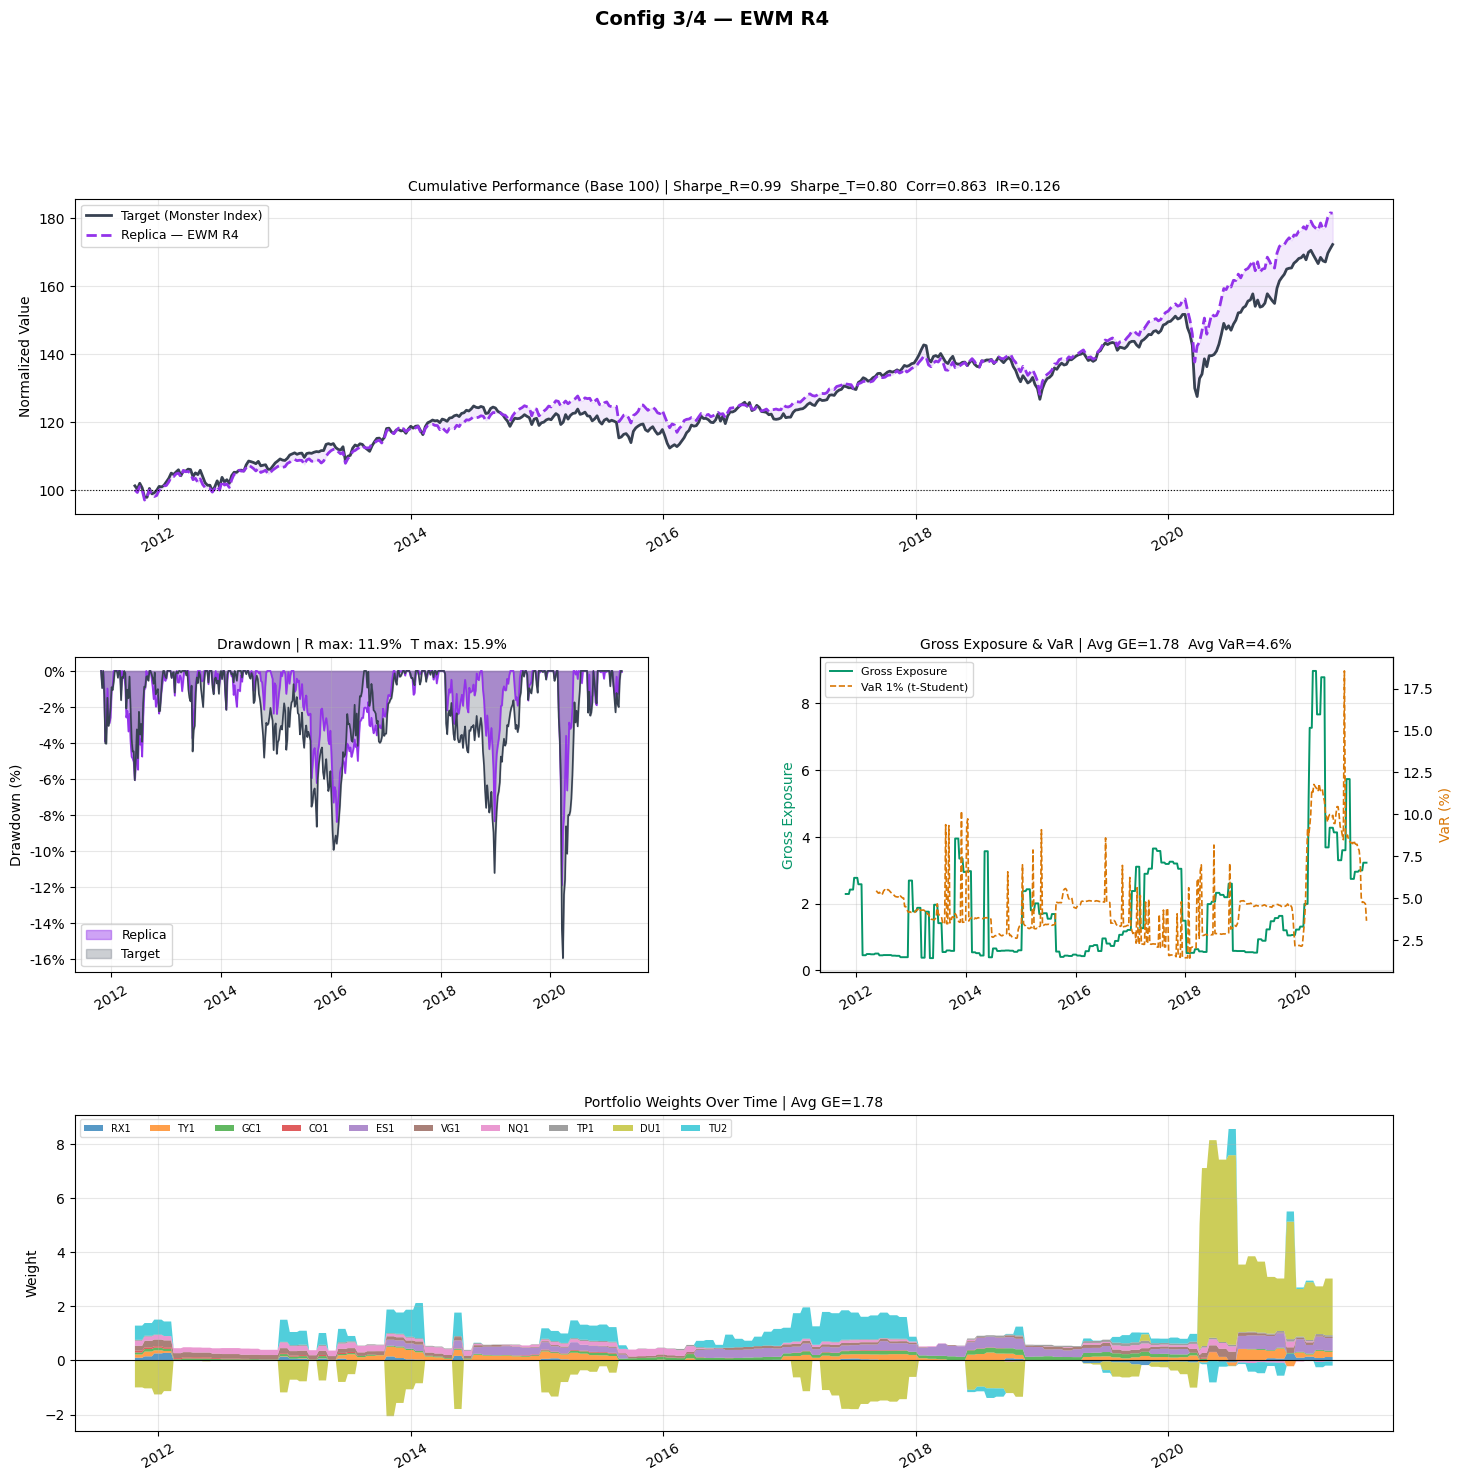

  Saved: dashboard_cfg3_EWM_R4.png


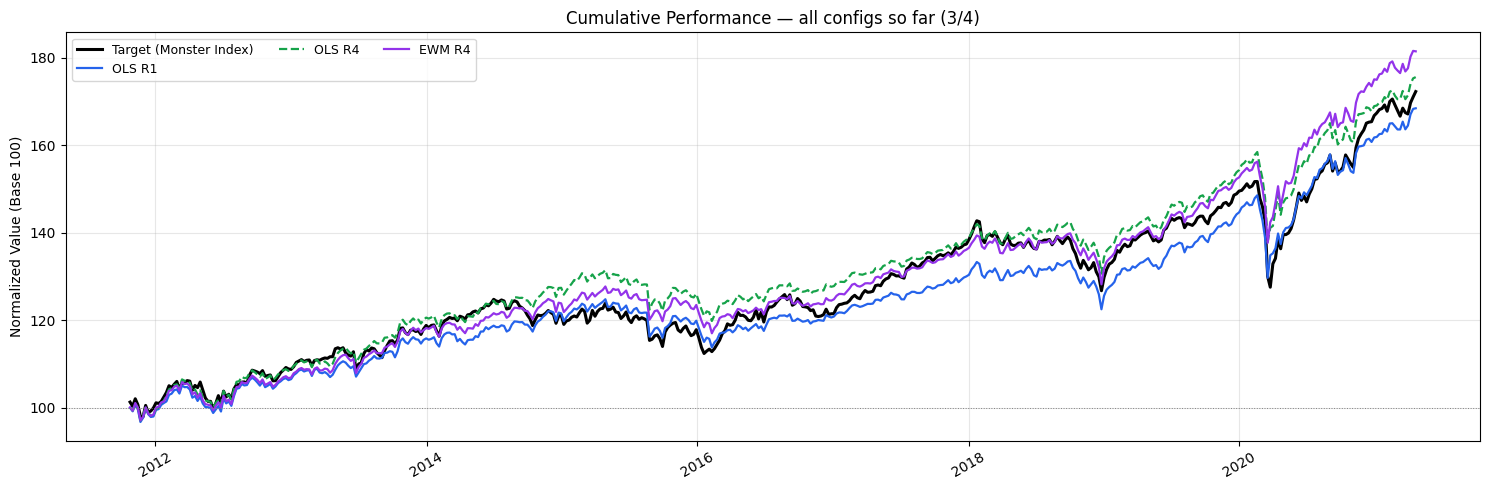


  Accumulated metrics (3/4):


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
OLS R1,-0.081,3.80,0.862,0.88,5.68,6.47,12.7,1.47,10.06,2.77e-05
OLS R4,0.036,3.64,0.874,0.94,6.12,6.54,13.0,1.48,4.51,2.55e-05
EWM R4,0.126,3.79,0.863,0.99,6.47,6.52,11.9,1.78,5.36,2.75e-05



  CONFIG 4/4 : OLS R4 LO
  Rebal=4w  EWM=False  LongOnly=True

  IR=-0.034  TEV=3.53%  Corr=0.883  Sharpe_R=0.89  MaxDD_R=12.3%  AvgTO=2.61  AvgGE=0.98


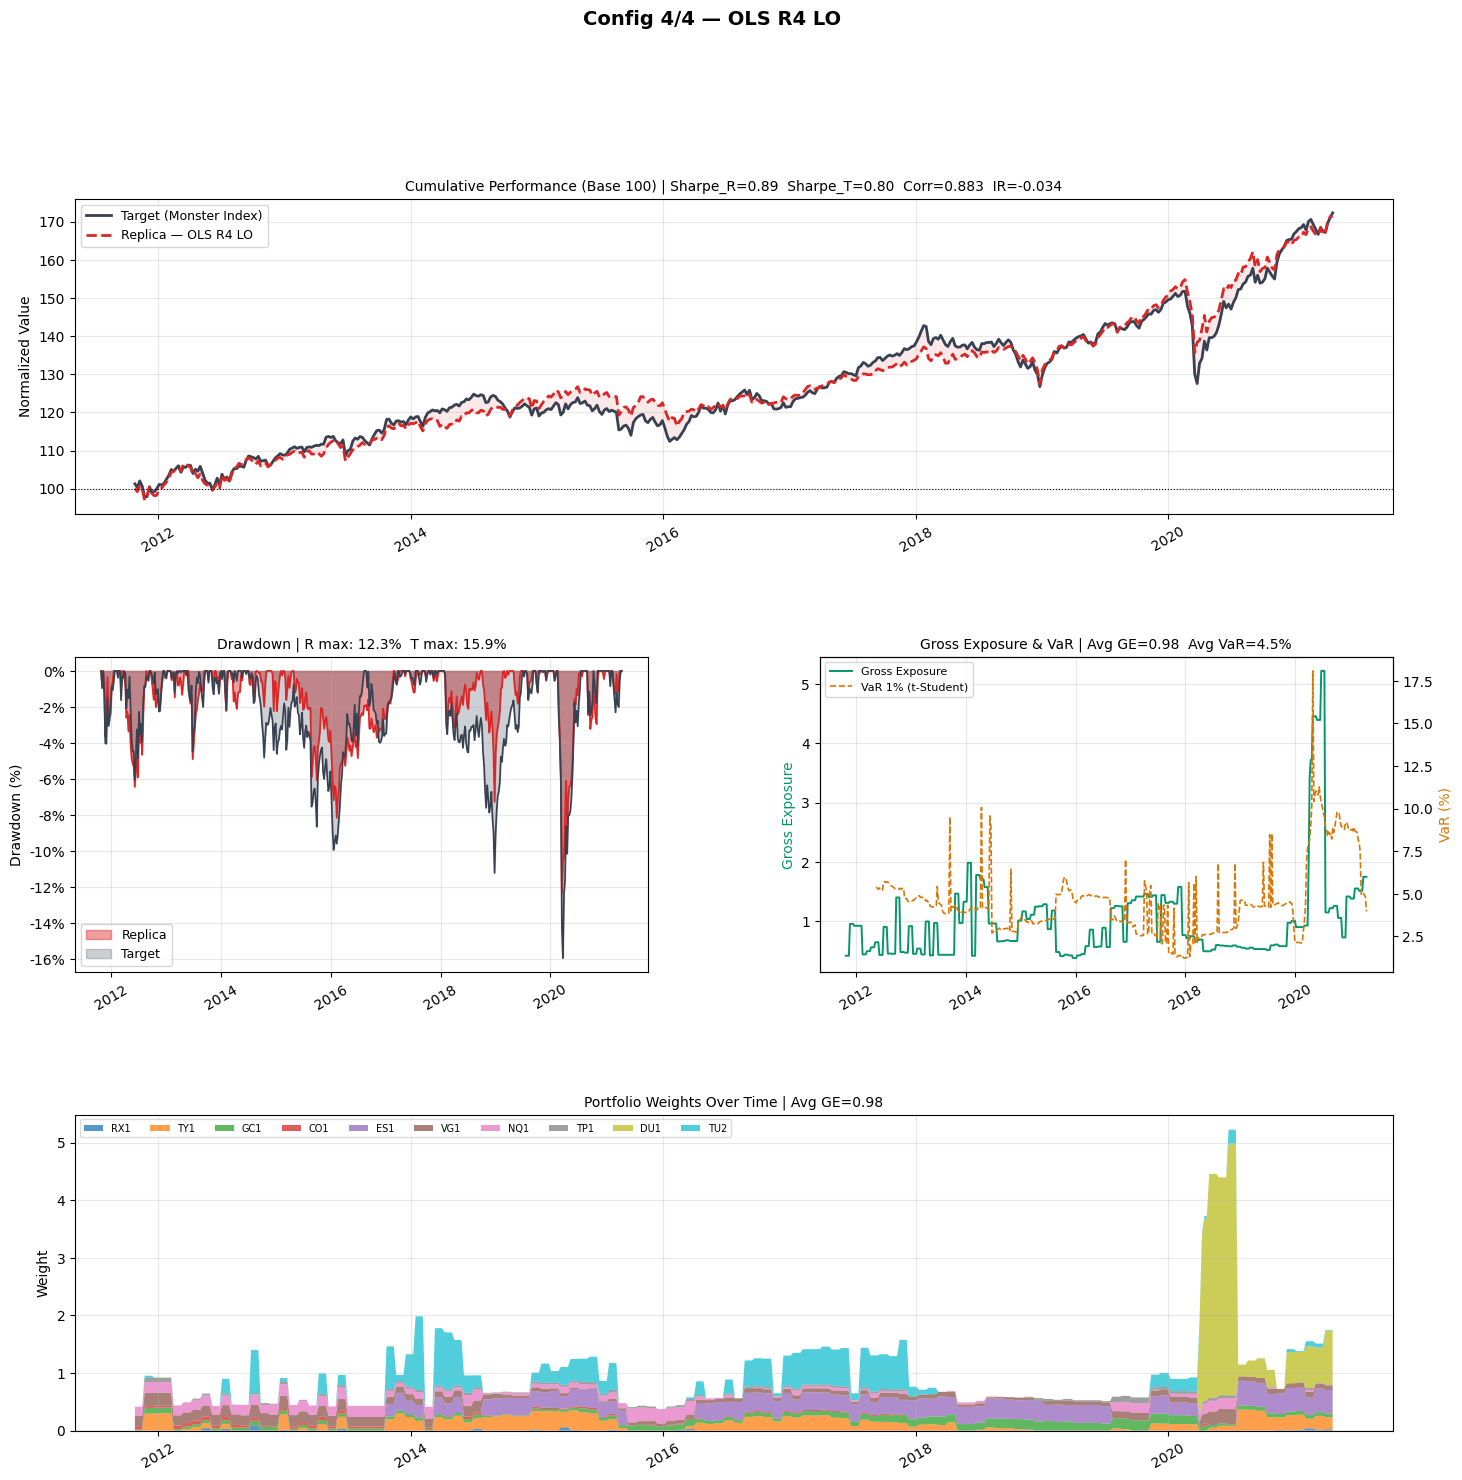

  Saved: dashboard_cfg4_OLS_R4_LO.png


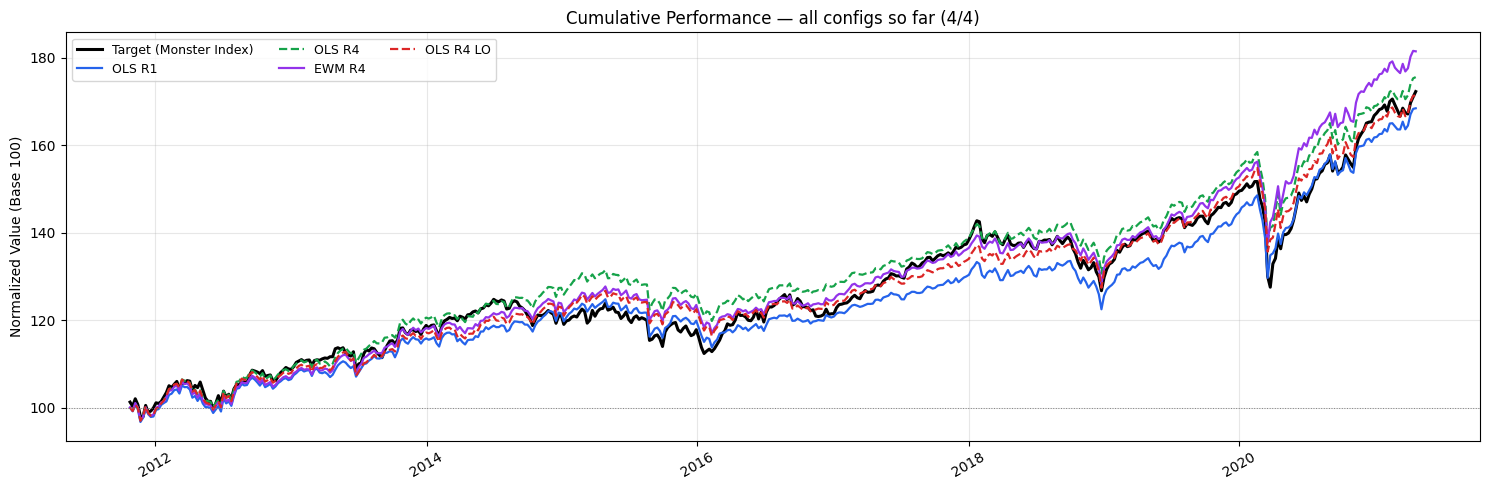


  Accumulated metrics (4/4):


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
OLS R1,-0.081,3.80,0.862,0.88,5.68,6.47,12.7,1.47,10.06,2.77e-05
OLS R4,0.036,3.64,0.874,0.94,6.12,6.54,13.0,1.48,4.51,2.55e-05
EWM R4,0.126,3.79,0.863,0.99,6.47,6.52,11.9,1.78,5.36,2.75e-05
OLS R4 LO,-0.034,3.53,0.883,0.89,5.87,6.56,12.3,0.98,2.61,2.39e-05


In [12]:
# ── colour palette for cumulative return overlay ──────────────────────────────
PALETTE = ["#2563EB", "#16A34A", "#9333EA", "#DC2626"]

max_window = max(rolling_windows)

if "prob_vol_B" not in dir():
    prob_vol_B = None

for cfg_idx, cfg in enumerate(CONFIGS):

    label      = cfg["label"]
    REBAL_FREQ = cfg["REBAL_FREQ"]
    USE_EWM    = cfg["USE_EWM"]
    LONG_ONLY  = cfg["LONG_ONLY"]

    print(f"\n{'='*70}")
    print(f"  CONFIG {cfg_idx+1}/{N_CONFIGS} : {label}")
    print(f"  Rebal={REBAL_FREQ}w  EWM={USE_EWM}  LongOnly={LONG_ONLY}")
    print(f"{'='*70}")

    # ── storage ──────────────────────────────────────────────────────────────
    y_pred_list = []; y_test_list = []
    weights_list = []; ge_list = []; var_list = []
    dates_list = []
    best_alpha_h = []; best_l1_h = []; best_window_h = []

    _cached_w         = np.zeros(X_values.shape[1])
    _cached_intercept = 0.0
    _cached_alpha     = None; _cached_l1     = None
    _cached_window    = None

    # ── rolling loop ─────────────────────────────────────────────────────────
    for i in range(max_window, len(X_values)):

        step         = i - max_window
        should_refit = (step % REBAL_FREQ == 0)

        if should_refit:
            best_score = -np.inf
            best_alpha = best_l1 = best_window = None

            # Pre-compute VIF per rolling window on training data only (no lookahead)
            vif_cache = {}
            for rw in rolling_windows:
                X_rw   = X_values[i - rw : i]
                y_rw   = y_values[i - rw : i]
                valid  = np.isfinite(X_rw).all(axis=1) & np.isfinite(y_rw)
                X_rw_c = X_rw[valid]
                vif_cache[rw] = (
                    select_features_by_vif(
                        X_rw_c, threshold=VIF_THRESHOLD, min_features=VIF_MIN_FEATURES
                    ) if X_rw_c.shape[0] >= 2 else np.arange(X_values.shape[1])
                )

            for rw, al, l1 in product(rolling_windows, alphas, l1_ratios):
                sel_idx = vif_cache[rw]
                if sel_idx.size == 0:
                    continue

                X_rw  = X_values[i - rw : i]
                y_rw  = y_values[i - rw : i]
                valid = np.isfinite(X_rw).all(axis=1) & np.isfinite(y_rw)
                X_rw_c, y_rw_c = X_rw[valid], y_rw[valid]
                if len(y_rw_c) < 6:
                    continue

                sc = evaluate_config_with_tss(
                    X_rw_c[:, sel_idx], y_rw_c, al, l1, n_splits=3,
                    positive=LONG_ONLY, use_ewm=USE_EWM
                )
                if np.isfinite(sc) and sc > best_score:
                    best_score = sc; best_alpha = al; best_l1 = l1; best_window = rw

            if best_window is None:
                weights = _cached_w.copy()
            else:
                X_raw = X_values[i - best_window : i]
                y_raw = y_values[i - best_window : i]
                mask  = np.isfinite(X_raw).all(axis=1) & np.isfinite(y_raw)
                X_tr  = X_raw[mask]; y_tr = y_raw[mask]

                if len(y_tr) == 0:
                    weights = _cached_w.copy()
                else:
                    sel = select_features_by_vif(
                        X_tr, threshold=VIF_THRESHOLD, min_features=VIF_MIN_FEATURES
                    )
                    if sel.size == 0:
                        weights = _cached_w.copy()
                    else:
                        sw = compute_sample_weights(y_tr) if USE_EWM else None
                        w_sel, intercept_sel, _ = fit_elastic_net_scaled(
                            X_tr[:, sel], y_tr, best_alpha, best_l1,
                            sample_weight=sw, positive=LONG_ONLY
                        )
                        weights = np.zeros(X_values.shape[1])
                        weights[sel] = w_sel
                        _cached_intercept = intercept_sel

            _cached_alpha  = best_alpha; _cached_l1     = best_l1
            _cached_window = best_window
            _cached_w      = weights.copy()

        else:
            weights     = _cached_w.copy()
            best_alpha  = _cached_alpha; best_l1    = _cached_l1
            best_window = _cached_window
            intercept_sel = _cached_intercept

        # ── long-only safety clip ─────────────────────────────────────────────
        if LONG_ONLY:
            weights = np.maximum(weights, 0.0)

        # ── risk controls ─────────────────────────────────────────────────────
        w_prev = weights_list[-1].copy() if weights_list else np.zeros_like(weights)

        # Trim negligible weights to zero
        weights[np.abs(weights) < 0.01] = 0.0

        # Turnover gate
        if USE_TURNOVER_GATE and weights_list:
            proposed = np.sum(np.abs(weights - w_prev))
            if proposed < TURNOVER_THRESHOLD:
                weights = w_prev.copy(); turnover = 0.0
            else:
                turnover = proposed
        else:
            turnover = np.sum(np.abs(weights - w_prev))

        if LONG_ONLY:
            weights = np.maximum(weights, 0.0)

        # VaR constraint (GARCH Filtered Bootstrap)
        scaling_factor = 1.0
        if USE_VAR_CONSTRAINT and len(y_pred_list) >= 30:
            lbk  = min(52, len(y_pred_list))
            hist = np.array(y_pred_list[-lbk:], dtype=float)
            hist = hist[np.isfinite(hist)]
            if hist.size >= 30:
                try:
                    cv = var_filtered_bootstrap(hist, var_confidence, var_horizon)
                except Exception:
                    cv = var_garch_t(hist, var_confidence, var_horizon)
            else:
                cv = np.nan
            if np.isfinite(cv) and cv > max_var_threshold:
                scaling_factor = max_var_threshold / cv
                weights        = weights * scaling_factor
                if LONG_ONLY:
                    weights = np.maximum(weights, 0.0)

        ge = np.sum(np.abs(weights))

        cost    = (turnover / 2) * TRANSACTION_COST
        nx      = np.nan_to_num(X_values[i], nan=0.0, posinf=0.0, neginf=0.0)
        rep_ret = (nx @ weights + _cached_intercept) - cost

        y_pred_list.append(rep_ret)
        y_test_list.append(y_values[i])
        weights_list.append(weights)
        ge_list.append(ge)
        dates_list.append(dates_array[i])

        # Reporting VaR (Student-t)
        if len(y_pred_list) >= 30:
            lbk2 = min(52, len(y_pred_list))
            ev   = var_student_t(y_pred_list[-lbk2:], var_confidence, var_horizon)
        else:
            ev = np.nan
        var_list.append(ev)
        best_alpha_h.append(best_alpha); best_l1_h.append(best_l1)
        best_window_h.append(best_window)

    # ── convert to Series ────────────────────────────────────────────────────
    min_len = min(len(y_pred_list), len(dates_list))
    idx     = pd.DatetimeIndex(dates_list[:min_len])

    y_pred = pd.Series(np.asarray(y_pred_list)[:min_len], index=idx, name="Replica")
    y_test = pd.Series(np.asarray(y_test_list)[:min_len], index=idx, name="Target")
    ge_s   = pd.Series(np.asarray(ge_list)[:min_len],     index=idx, name="GE")
    var_s  = pd.Series(np.asarray(var_list)[:min_len],    index=idx, name="VaR")
    weights_arr = np.asarray(weights_list)[:min_len]
    weights_df  = pd.DataFrame(weights_arr, index=idx, columns=futures_ret.columns)

    # ── metrics ───────────────────────────────────────────────────────────────
    m = compute_metrics(y_pred, y_test, weights_list[:min_len])
    m["label"] = label
    all_results.append({
        "label": label, "metrics": m,
        "y_pred": y_pred, "y_test": y_test,
        "ge": ge_s, "var": var_s, "weights_df": weights_df
    })

    print(f"\n  IR={m['IR']:.3f}  TEV={m['TEV']*100:.2f}%  Corr={m['Corr']:.3f}"
          f"  Sharpe_R={m['Sharpe_R']:.2f}  MaxDD_R={m['MaxDD_R']*100:.1f}%"
          f"  AvgTO={m['AvgTO']:.2f}  AvgGE={ge_s.mean():.2f}")

    # ──────────────────────────────────────────────────────────────────────────
    # INDIVIDUAL DASHBOARD  (4 panels: cumulative, drawdown, GE+VaR, weights)
    # ──────────────────────────────────────────────────────────────────────────
    C_REP = PALETTE[cfg_idx]; C_TGT = "#374151"
    cum_r = (1 + y_pred).cumprod() * 100
    cum_t = (1 + y_test).cumprod() * 100
    dd_r  = 1 - (1+y_pred).cumprod() / (1+y_pred).cumprod().cummax()
    dd_t  = 1 - (1+y_test).cumprod() / (1+y_test).cumprod().cummax()
    te_roll = (y_pred - y_test).rolling(52).std() * np.sqrt(52) * 100

    fig = plt.figure(figsize=(17, 16))
    fig.suptitle(f"Config {cfg_idx+1}/{N_CONFIGS} — {label}", fontsize=14, fontweight="bold", y=0.998)
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.30)
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, :])

    fmt = mdates.DateFormatter("%Y"); loc = mdates.YearLocator(2)

    # Panel 1 — cumulative performance
    ax1.plot(cum_t.index, cum_t.values, color=C_TGT, lw=2.0, label="Target (Monster Index)")
    ax1.plot(cum_r.index, cum_r.values, color=C_REP, lw=2.0, ls="--",
             label=f"Replica — {label}")
    ax1.fill_between(cum_t.index, cum_t.values, cum_r.values, alpha=0.10, color=C_REP)
    ax1.axhline(100, color="black", lw=0.8, ls=":")
    ax1.set_title(f"Cumulative Performance (Base 100) | "
                  f"Sharpe_R={m['Sharpe_R']:.2f}  Sharpe_T={m['Sharpe_T']:.2f}  "
                  f"Corr={m['Corr']:.3f}  IR={m['IR']:.3f}", fontsize=10)
    ax1.set_ylabel("Normalized Value"); ax1.legend(fontsize=9)
    ax1.xaxis.set_major_formatter(fmt); ax1.xaxis.set_major_locator(loc)
    ax1.grid(True, alpha=0.3); ax1.tick_params(axis="x", rotation=30)

    # Panel 2 — drawdown
    ax2.fill_between(dd_r.index, -dd_r*100, 0, color=C_REP, alpha=0.45, label="Replica")
    ax2.fill_between(dd_t.index, -dd_t*100, 0, color=C_TGT, alpha=0.25, label="Target")
    ax2.plot(dd_r.index, -dd_r*100, color=C_REP, lw=1.2)
    ax2.plot(dd_t.index, -dd_t*100, color=C_TGT, lw=1.2)
    ax2.set_title(f"Drawdown | R max: {m['MaxDD_R']*100:.1f}%  T max: {m['MaxDD_T']*100:.1f}%",
                  fontsize=10)
    ax2.set_ylabel("Drawdown (%)"); ax2.legend(fontsize=9)
    ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
    ax2.xaxis.set_major_formatter(fmt); ax2.xaxis.set_major_locator(loc)
    ax2.grid(True, alpha=0.3); ax2.tick_params(axis="x", rotation=30)

    # Panel 3 — Gross Exposure + VaR
    ax3b = ax3.twinx()
    ax3.plot(ge_s.index, ge_s.values, color="#059669", lw=1.4, label="Gross Exposure")
    ax3b.plot(var_s.index, var_s.values*100, color="#D97706", lw=1.2, ls="--", label="VaR 1% (t-Student)")
    ax3.set_title(f"Gross Exposure & VaR | Avg GE={ge_s.mean():.2f}  "
                  f"Avg VaR={var_s.mean()*100:.1f}%", fontsize=10)
    ax3.set_ylabel("Gross Exposure", color="#059669")
    ax3b.set_ylabel("VaR (%)", color="#D97706")
    lines1, labels1 = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3b.get_legend_handles_labels()
    ax3.legend(lines1+lines2, labels1+labels2, fontsize=8)
    ax3.xaxis.set_major_formatter(fmt); ax3.xaxis.set_major_locator(loc)
    ax3.grid(True, alpha=0.3); ax3.tick_params(axis="x", rotation=30)

    # Panel 4 — weights stacked area
    pos_w = weights_df.clip(lower=0); neg_w = weights_df.clip(upper=0)
    colors_w = plt.cm.tab10(np.linspace(0, 1, len(weights_df.columns)))
    ax4.stackplot(weights_df.index, pos_w.T.values, labels=weights_df.columns.tolist(),
                  colors=colors_w, alpha=0.75)
    ax4.stackplot(weights_df.index, neg_w.T.values, colors=colors_w, alpha=0.75)
    ax4.axhline(0, color="black", lw=0.8)
    ax4.set_title(f"Portfolio Weights Over Time | Avg GE={ge_s.mean():.2f}", fontsize=10)
    ax4.set_ylabel("Weight")
    ax4.legend(loc="upper left", fontsize=7, ncol=len(weights_df.columns),
               bbox_to_anchor=(0, 1.0), framealpha=0.7)
    ax4.xaxis.set_major_formatter(fmt); ax4.xaxis.set_major_locator(loc)
    ax4.grid(True, alpha=0.3); ax4.tick_params(axis="x", rotation=30)

    plt.savefig(f"dashboard_cfg{cfg_idx+1}_{label.replace(' ','_')}.png",
                dpi=120, bbox_inches="tight")
    plt.show()
    print(f"  Saved: dashboard_cfg{cfg_idx+1}_{label.replace(' ','_')}.png")

    # ──────────────────────────────────────────────────────────────────────────
    # ACCUMULATED COMPARISON
    # ──────────────────────────────────────────────────────────────────────────
    n_done = len(all_results)
    fig2, ax_cmp = plt.subplots(figsize=(15, 5))

    cum_tgt = (1 + all_results[0]["y_test"]).cumprod() * 100
    ax_cmp.plot(cum_tgt.index, cum_tgt.values, color="black", lw=2.2,
                label="Target (Monster Index)")

    for k, res in enumerate(all_results):
        cum_k = (1 + res["y_pred"]).cumprod() * 100
        ax_cmp.plot(cum_k.index, cum_k.values, color=PALETTE[k], lw=1.6,
                    ls="--" if k % 2 else "-", label=res["label"])

    ax_cmp.axhline(100, color="grey", lw=0.7, ls=":")
    ax_cmp.set_title(f"Cumulative Performance — all configs so far ({n_done}/{N_CONFIGS})", fontsize=12)
    ax_cmp.set_ylabel("Normalized Value (Base 100)")
    ax_cmp.legend(fontsize=9, ncol=3)
    ax_cmp.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax_cmp.xaxis.set_major_locator(mdates.YearLocator(2))
    ax_cmp.grid(True, alpha=0.3); ax_cmp.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.savefig(f"comparison_up_to_cfg{cfg_idx+1}.png", dpi=120, bbox_inches="tight")
    plt.show()

    # Metrics table
    rows = []
    for res in all_results:
        mt = res["metrics"]
        rows.append({
            "Config":      res["label"],
            "IR":          round(mt["IR"],  3),
            "TEV (%)":     round(mt["TEV"]*100, 2),
            "Corr":        round(mt["Corr"], 3),
            "Sharpe_R":    round(mt["Sharpe_R"], 2),
            "Ret_R (%)":   round(mt["Ret_R"]*100, 2),
            "Vol_R (%)":   round(mt["Vol_R"]*100, 2),
            "MaxDD_R (%)": round(mt["MaxDD_R"]*100, 1),
            "AvgGE":       round(float(res["ge"].mean()), 2),
            "AvgTO":       round(mt["AvgTO"], 2),
            "MSE":         f"{mt['MSE']:.2e}",
        })
    tbl = pd.DataFrame(rows).set_index("Config")
    print(f"\n  Accumulated metrics ({n_done}/{N_CONFIGS}):")
    from IPython.display import display
    display(tbl)

We observe that moving from weekly to monthly rebalancing (OLS R1 → OLS R4) reduces turnover sharply (10.06 → 4.51) while improving all tracking metrics (TEV 3.80% → 3.64%, Corr 0.862 → 0.874, IR −0.081 → 0.036). Adding exponential weighting (EWM R4) further improves IR (0.036 → 0.126) and Sharpe (0.94 → 0.99), but at the cost of higher TEV, lower Corr, and increased gross exposure and turnover; the gains do not justify the added complexity. The long-only constraint (OLS R4 LO) achieves the best tracking overall — lowest TEV (3.53%), highest Corr (0.883), lowest gross exposure (0.98) and lowest turnover (2.61) — confirming that long/short offsetting was the primary source of instability in the unconstrained models. Despite a mildly negative IR (−0.034), OLS R4 LO remains the preferred specification.

Although our final model yielded good results, we decided to explore an additional approach suggested by the literature: pooling, i.e. a model combination approach.


## Pooling

**Reference**: O'Doherty, Savin & Tiwari (2017), *Review of Finance* — "Hedge Fund Replication: A Model Combination Approach"

**Why?**   
               Futures with similar characteristics are pooled into composite factors before 
entering the model. This serves multiple purposes: it naturally **reduces 
multicollinearity** among regressors by collapsing redundant signals into a single 
representative exposure, without the computational overhead of iterative procedures 
such as VIF filtering. Pooling also reduces the number of distinct positions in the 
portfolio, limiting transaction costs without requiring additional explicit constraints. 
More broadly, aggregating contracts with similar risk profiles increases the effective 
number of observations per factor, stabilising coefficient estimates and improving 
out-of-sample replication metrics.

### Key idea
Instead of a single best-fit model, we pool **four factor-group models** by assigning optimal weights
via the **log score criterion**: a model that assigns high probability to the returns that actually
materialize receives a higher weight.

Factor groups (adapted to our futures universe)
| Group | Futures | Motivation |
|-------|---------|------------|
| US Equity | ES1, NQ1 | domestic equity exposure |
| Intl Equity | VG1, TP1 | European & Asian equity |
| Fixed Income | TY1, TU2, RX1, DU1 | US & EU rates / duration |
| Commodities | GC1, CO1 | gold & crude oil |

Algorithm
1. **Rolling OLS** (54-week window, no intercept) per group — yields per-group betas
2. **Bayesian predictive density** (Student-t, Zellner 1971) per group — *how probable was this week's return under each model?*
3. **Log Score optimisation** (expanding window) — find $w^*$ maximising $\sum_t \log \bigl(\sum_i w_i \, p_i(r_t)\bigr)$
4. **Clone return** = $\sum_i w_i^* \sum_k \hat{\beta}_{k,i} f_{k,t}$ (net of transaction costs)


In [13]:
# ── Model Combination──────────────────────────


# Four factor groups — paper Section 3.3.a adapted to our futures
FACTOR_GROUPS_DEF = {
    'US Equity'   : ['ES1', 'NQ1'],
    'Intl Equity' : ['VG1', 'TP1'],
    'Fixed Income': ['TY1', 'TU2', 'RX1', 'DU1'],
    'Commodities' : ['GC1', 'CO1'],
}

available_futures_mc = list(futures_ret.columns)

FACTOR_GROUPS_MC = {
    gname: [f for f in gfactors if f in available_futures_mc]
    for gname, gfactors in FACTOR_GROUPS_DEF.items()
    if any(f in available_futures_mc for f in gfactors)
}

MODEL_NAMES_MC = list(FACTOR_GROUPS_MC.keys())
N_MODELS_MC    = len(MODEL_NAMES_MC)

print("Factor groups used:")
for g, fs in FACTOR_GROUPS_MC.items():
    print(f"  {g:20s}: {fs}")
print(f"\nTotal models in pool: {N_MODELS_MC}")


Factor groups used:
  US Equity           : ['ES1', 'NQ1']
  Intl Equity         : ['VG1', 'TP1']
  Fixed Income        : ['TY1', 'TU2', 'RX1', 'DU1']
  Commodities         : ['GC1', 'CO1']

Total models in pool: 4


###  Bayesian predictive log-density (Eq. 12 of O'Doherty et al.)

Under OLS with uninformative prior and normal errors, the predictive distribution for a new
observation $r_t$ conditional on current factors $\mathbf{f}_t$ is a Student-t:

$$p(r_t \mid \mathbf{R}_{t-1}, \mathbf{F}_{t-1}, \mathbf{f}_t) = t_\nu\!\left(\hat{\mathbf{B}}'\mathbf{f}_t,\; \frac{S}{\nu}\bigl(1 + \mathbf{f}_t'(\mathbf{F}'\mathbf{F})^{-1}\mathbf{f}_t\bigr)\right)$$

where $\nu = n - K$ (degrees of freedom), $S$ = residual sum of squares, $\hat{\mathbf{B}}$ = OLS estimate.


In [14]:
# ── Bayesian predictive log-density ─────────────────────────────────────
def predictive_log_density(r_t, f_t_vec, F_train, R_train):
    """
    Student-t predictive log-density for a new target return r_t,
    given current factor vector f_t_vec and training data (F_train, R_train).

    Implements Eq. 12 of O'Doherty, Savin & Tiwari (2017):
      - OLS without intercept (pure factor model)
      - Bayesian uninformative prior (Zellner 1971)
      - Returns NaN if the problem is underdetermined
    """
    n, K = F_train.shape
    nu   = n - K          # degrees of freedom
    if nu <= 2:
        return np.nan

    # OLS (regression through origin, no intercept)
    try:
        B_hat, _, _, _ = np.linalg.lstsq(F_train, R_train, rcond=None)
    except Exception:
        return np.nan

    residuals = R_train - F_train @ B_hat
    S = float(residuals @ residuals)
    if S <= 1e-14:
        return np.nan

    s2 = S / nu           # posterior variance estimate

    # Prediction scaling: 1 + f_t'(F'F)^{-1}f_t
    try:
        FtF_inv    = np.linalg.inv(F_train.T @ F_train)
    except np.linalg.LinAlgError:
        FtF_inv    = np.linalg.pinv(F_train.T @ F_train)
    pred_factor = 1.0 + float(f_t_vec @ FtF_inv @ f_t_vec)
    pred_scale  = np.sqrt(max(s2 * pred_factor, 1e-14))

    loc = float(B_hat @ f_t_vec)
    return student_t.logpdf(r_t, df=nu, loc=loc, scale=pred_scale)


# ── Log-score optimal weight optimisation ────────────────────────────────
def optimize_log_score_weights(log_density_matrix):
    """
    Find weights w* = argmax_{w} sum_t log(sum_i w_i * p_i(r_t))
    s.t. w >= 0, sum(w) = 1  (Eq. 15 of O'Doherty et al.)

    Parameters
    ----------
    log_density_matrix : ndarray (T, M)
        Per-model log-densities over T evaluation periods.

    Returns
    -------
    w_opt : ndarray (M,)
    """
    M  = log_density_matrix.shape[1]

    # Stabilise: shift log-densities by row-maximum before exponentiating
    row_max  = np.nanmax(log_density_matrix, axis=1, keepdims=True)
    p_matrix = np.exp(log_density_matrix - row_max)  # relative densities
    p_matrix = np.nan_to_num(p_matrix, nan=0.0, posinf=0.0)

    # Rows where ALL models give NaN — drop them
    valid_rows = p_matrix.sum(axis=1) > 0
    p_matrix   = p_matrix[valid_rows]

    def neg_ls(w):
        mix = p_matrix @ w
        mix = np.maximum(mix, 1e-300)
        return -np.sum(np.log(mix))

    def neg_ls_grad(w):
        mix = np.maximum(p_matrix @ w, 1e-300)
        return -(p_matrix / mix[:, None]).sum(axis=0)

    constraints = {'type': 'eq', 'fun': lambda w: w.sum() - 1.0}
    bounds      = [(0.0, 1.0)] * M
    best_val, best_w = np.inf, np.ones(M) / M

    starts = [np.ones(M) / M] + [
        (np.eye(M)[i] * 0.8 + np.ones(M) * 0.2 / M) for i in range(M)
    ]
    for w0 in starts:
        try:
            res = minimize(
                neg_ls, w0, jac=neg_ls_grad,
                method='SLSQP', bounds=bounds, constraints=constraints,
                options={'ftol': 1e-10, 'maxiter': 500}
            )
            if res.success and res.fun < best_val:
                best_val, best_w = res.fun, res.x
        except Exception:
            pass

    best_w = np.maximum(best_w, 0.0)
    best_w /= best_w.sum()
    return best_w


print("Helper functions defined.")
print("  predictive_log_density    — Bayesian Student-t log-density (Eq. 12)")
print("  optimize_log_score_weights — SLSQP log-score maximisation (Eq. 15)")


Helper functions defined.
  predictive_log_density    — Bayesian Student-t log-density (Eq. 12)
  optimize_log_score_weights — SLSQP log-score maximisation (Eq. 15)


### Rolling Loop

**Design choices** (mirroring the paper's Section 3.3.c, adapted for weekly data):
- Rolling window of **54 weeks** (~1 year) for OLS factor-loading estimation.
        The rolling loop consistently favours the 54-week window, which is the shortest available and therefore the most parsimonious in terms of features. This revealed preference for a compact, low-noise input space is fully consistent with the rationale for pooling — both choices reflect a structural bias toward simpler, more stable representations over richer but noisier ones.
- Minimum of **54 weekly density observations** before the first weight optimisation
- **Expanding window** of past densities used to update model weights each period
- Gross leverage capped at **2×** 
- Transaction cost of **0.04% per leg** 



In [15]:
# ════════════════════════════════════════════════════════════════════
# MODEL COMBINATION — ROLLING LOOP 
# ════════════════════════════════════════════════════════════════════
#
# Correct ordering (Section 3.3.c of the paper):
#   1. Compute log-density for period i using r_t      →  ld_i
#   2. Optimise weights on log_dens_hist[0 … i-1]      →  does NOT include ld_i
#   3. Construct clone return for period i
#   4. Append ld_i to log_dens_hist                     →  used from period i+1 onward
#
# This ensures that w* at period i are computed BEFORE observing r_t,
# exactly as in the paper (Eq. 16-18): w*_{T} applied at period T+1.

ROLL_WIN_MC     = 54    # OLS estimation window (weeks, ~1 year)
MIN_DENS_OBS_MC = 54    # minimum observations before first weight optimisation
MAX_LEV_MC      = 2.0   # gross leverage cap
TC_MC           = 0.0004 # transaction cost (round-trip per unit of turnover)

# ── Data alignment ────────────────────────────────────────────────────
common_mc  = futures_ret.index.intersection(target.index)
X_mc       = futures_ret.loc[common_mc].copy()
y_mc       = target.loc[common_mc].copy()

X_mc_vals  = X_mc.values.astype(float)
y_mc_vals  = y_mc.values.astype(float)
dates_mc   = np.array(X_mc.index)
col_names  = list(X_mc.columns)
N_OBS_MC   = len(y_mc_vals)

group_col_idx = {
    gname: np.array([col_names.index(f) for f in gfactors], dtype=int)
    for gname, gfactors in FACTOR_GROUPS_MC.items()
}

# ── Storage ───────────────────────────────────────────────────────────────
y_pred_MC      = []
y_test_MC      = []
weights_MC     = []
turnover_MC    = []
ge_MC          = []
dates_out_MC   = []
model_wts_hist = []   # optimal model weights for each OOS period

# Accumulate per-model log-densities from PAST periods.
# log_dens_hist[t] contains the densities computed AT period t,
# but is appended AFTER the clone return for t has been produced.
log_dens_hist  = []

print(f"Data: {N_OBS_MC} weekly observations")
print(f"First OLS fit: week {ROLL_WIN_MC}")
print(f"First weight optimisation: week {ROLL_WIN_MC + MIN_DENS_OBS_MC}")
print(f"First clone return (leakage-free): week {ROLL_WIN_MC + MIN_DENS_OBS_MC + 1}")
print("Starting loop … (1–2 min)")

for i in range(ROLL_WIN_MC, N_OBS_MC):

    # ── Training window: [i-54, i-1] — period i is EXCLUDED ──────────
    X_tr = X_mc_vals[i - ROLL_WIN_MC : i]
    y_tr = y_mc_vals[i - ROLL_WIN_MC : i]

    f_t  = X_mc_vals[i]   # current factor values (observable at decision time)
    r_t  = y_mc_vals[i]   # true target return — used ONLY for the log-density

    # ── STEP 1: per-model predictive log-density at period i ──────────
    # r_t is used here only to evaluate "how likely was this outcome"
    # under each model estimated on the past window.
    ld_i    = np.zeros(N_MODELS_MC)
    betas_i = {}

    for m, (gname, gcols) in enumerate(group_col_idx.items()):
        F_g   = X_tr[:, gcols]
        f_t_g = f_t[gcols]

        valid  = np.isfinite(F_g).all(axis=1) & np.isfinite(y_tr)
        F_g_v  = F_g[valid]
        y_tr_v = y_tr[valid]

        K_g = F_g_v.shape[1]
        if len(y_tr_v) < K_g + 3:
            ld_i[m]        = np.nan
            betas_i[gname] = np.zeros(K_g)
            continue

        ld_i[m] = predictive_log_density(r_t, f_t_g, F_g_v, y_tr_v)

        try:
            b, _, _, _ = np.linalg.lstsq(F_g_v, y_tr_v, rcond=None)
            betas_i[gname] = b
        except Exception:
            betas_i[gname] = np.zeros(K_g)

    # ── STEP 2: optimise weights on log_dens_hist[0 … i-1] ───────────
    # CRITICAL: ld_i is NOT yet in log_dens_hist.
    # Weights w* are determined exclusively from PAST returns.
    if len(log_dens_hist) < MIN_DENS_OBS_MC:
        # Not enough history yet — do not produce a clone return.
        # Append ld_i NOW so history grows for future periods.
        log_dens_hist.append(ld_i)
        continue

    ld_mat = np.array(log_dens_hist)             # (n_hist, M) — excludes period i
    w_opt  = optimize_log_score_weights(ld_mat)  # w* computed before observing r_t
    model_wts_hist.append(w_opt.copy())

    # ── STEP 3: combine betas with optimal weights (Eq. 16) ──────────
    w_full = np.zeros(len(col_names))
    for m, (gname, gcols) in enumerate(group_col_idx.items()):
        b_g = betas_i.get(gname, np.zeros(len(gcols)))
        w_full[gcols] += w_opt[m] * b_g

    # ── Gross leverage cap ────────────────────────────────────────────
    ge = np.sum(np.abs(w_full))
    if ge > MAX_LEV_MC:
        w_full *= MAX_LEV_MC / ge
        ge      = MAX_LEV_MC
    w_full[np.abs(w_full) < 1e-4] = 0.0

    # ── Turnover and transaction cost ─────────────────────────────────
    w_prev   = weights_MC[-1] if weights_MC else np.zeros(len(col_names))
    turnover = float(np.sum(np.abs(w_full - w_prev)))
    cost     = turnover * TC_MC

    # ── Clone return (Eq. 18) — constructed BEFORE observing r_t ─────
    f_t_clean   = np.nan_to_num(f_t, nan=0.0)
    replica_ret = float(f_t_clean @ w_full) - cost

    # ── STEP 4: NOW append ld_i to history ───────────────────────────
    # From this point ld_i (which depends on r_t) is available,
    # but the clone return for period i has already been fixed.
    log_dens_hist.append(ld_i)

    # ── Store ─────────────────────────────────────────────────────────
    y_pred_MC.append(replica_ret)
    y_test_MC.append(r_t)
    weights_MC.append(w_full.copy())
    turnover_MC.append(turnover)
    ge_MC.append(ge)
    dates_out_MC.append(dates_mc[i])

# ── Convert to pandas ────────────────────────────────────────────────
y_pred_MC   = pd.Series(y_pred_MC,   index=dates_out_MC, name='MC Clone')
y_test_MC   = pd.Series(y_test_MC,   index=dates_out_MC, name='Target')
turnover_MC = pd.Series(turnover_MC, index=dates_out_MC)
ge_MC       = pd.Series(ge_MC,       index=dates_out_MC)
weights_MC_df = pd.DataFrame(
    np.array(weights_MC), index=dates_out_MC, columns=col_names
)
model_wts_df = pd.DataFrame(
    np.array(model_wts_hist), columns=MODEL_NAMES_MC
)

print(f"\nDone. OOS period: {y_pred_MC.index[0].date()} → {y_pred_MC.index[-1].date()}")
print(f"OOS observations (leakage-free): {len(y_pred_MC)}")


Data: 704 weekly observations
First OLS fit: week 54
First weight optimisation: week 108
First clone return (leakage-free): week 109
Starting loop … (1–2 min)

Done. OOS period: 2009-11-24 → 2021-04-20
OOS observations (leakage-free): 596


### Model Weights Evolution 


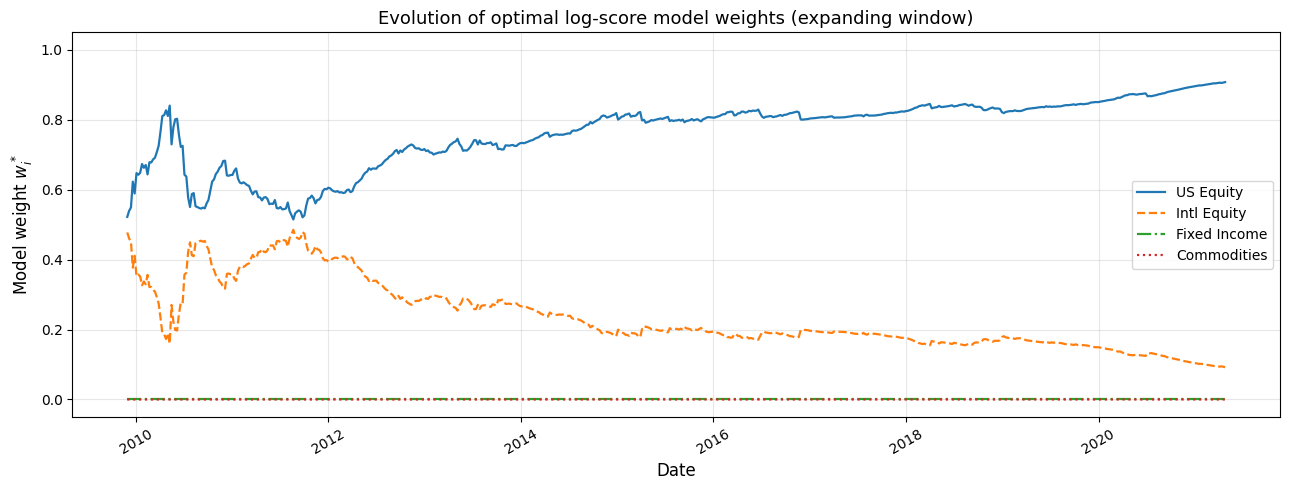

Average model weights over the OOS period:
  US Equity           : 0.764
  Intl Equity         : 0.236
  Fixed Income        : 0.000
  Commodities         : 0.000


In [16]:
fig, ax = plt.subplots(figsize=(13, 5))

colors_mc = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
styles_mc = ['-', '--', '-.', ':']

# Attach approximate dates to the weight history
# The first weight was computed at week ROLL_WIN_MC + MIN_DENS_OBS_MC
first_wt_date = dates_mc[ROLL_WIN_MC + MIN_DENS_OBS_MC]
last_wt_date  = dates_mc[-1]
wt_dates = pd.date_range(first_wt_date, periods=len(model_wts_df), freq='W')

for j, mname in enumerate(MODEL_NAMES_MC):
    ax.plot(
        wt_dates, model_wts_df[mname].values,
        label=mname, lw=1.6,
        color=colors_mc[j % len(colors_mc)],
        linestyle=styles_mc[j % len(styles_mc)]
    )

ax.set_ylim(-0.05, 1.05)
ax.set_ylabel('Model weight $w_i^*$', fontsize=12)
ax.set_xlabel('Date', fontsize=12)
ax.set_title(
    'Evolution of optimal log-score model weights (expanding window)',
    fontsize=13
)
ax.legend(fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('mc_model_weights.png', dpi=150, bbox_inches='tight')
plt.show()
print('Average model weights over the OOS period:')
for mname in MODEL_NAMES_MC:
    print(f'  {mname:20s}: {model_wts_df[mname].mean():.3f}')


### Results & Performance Metrics

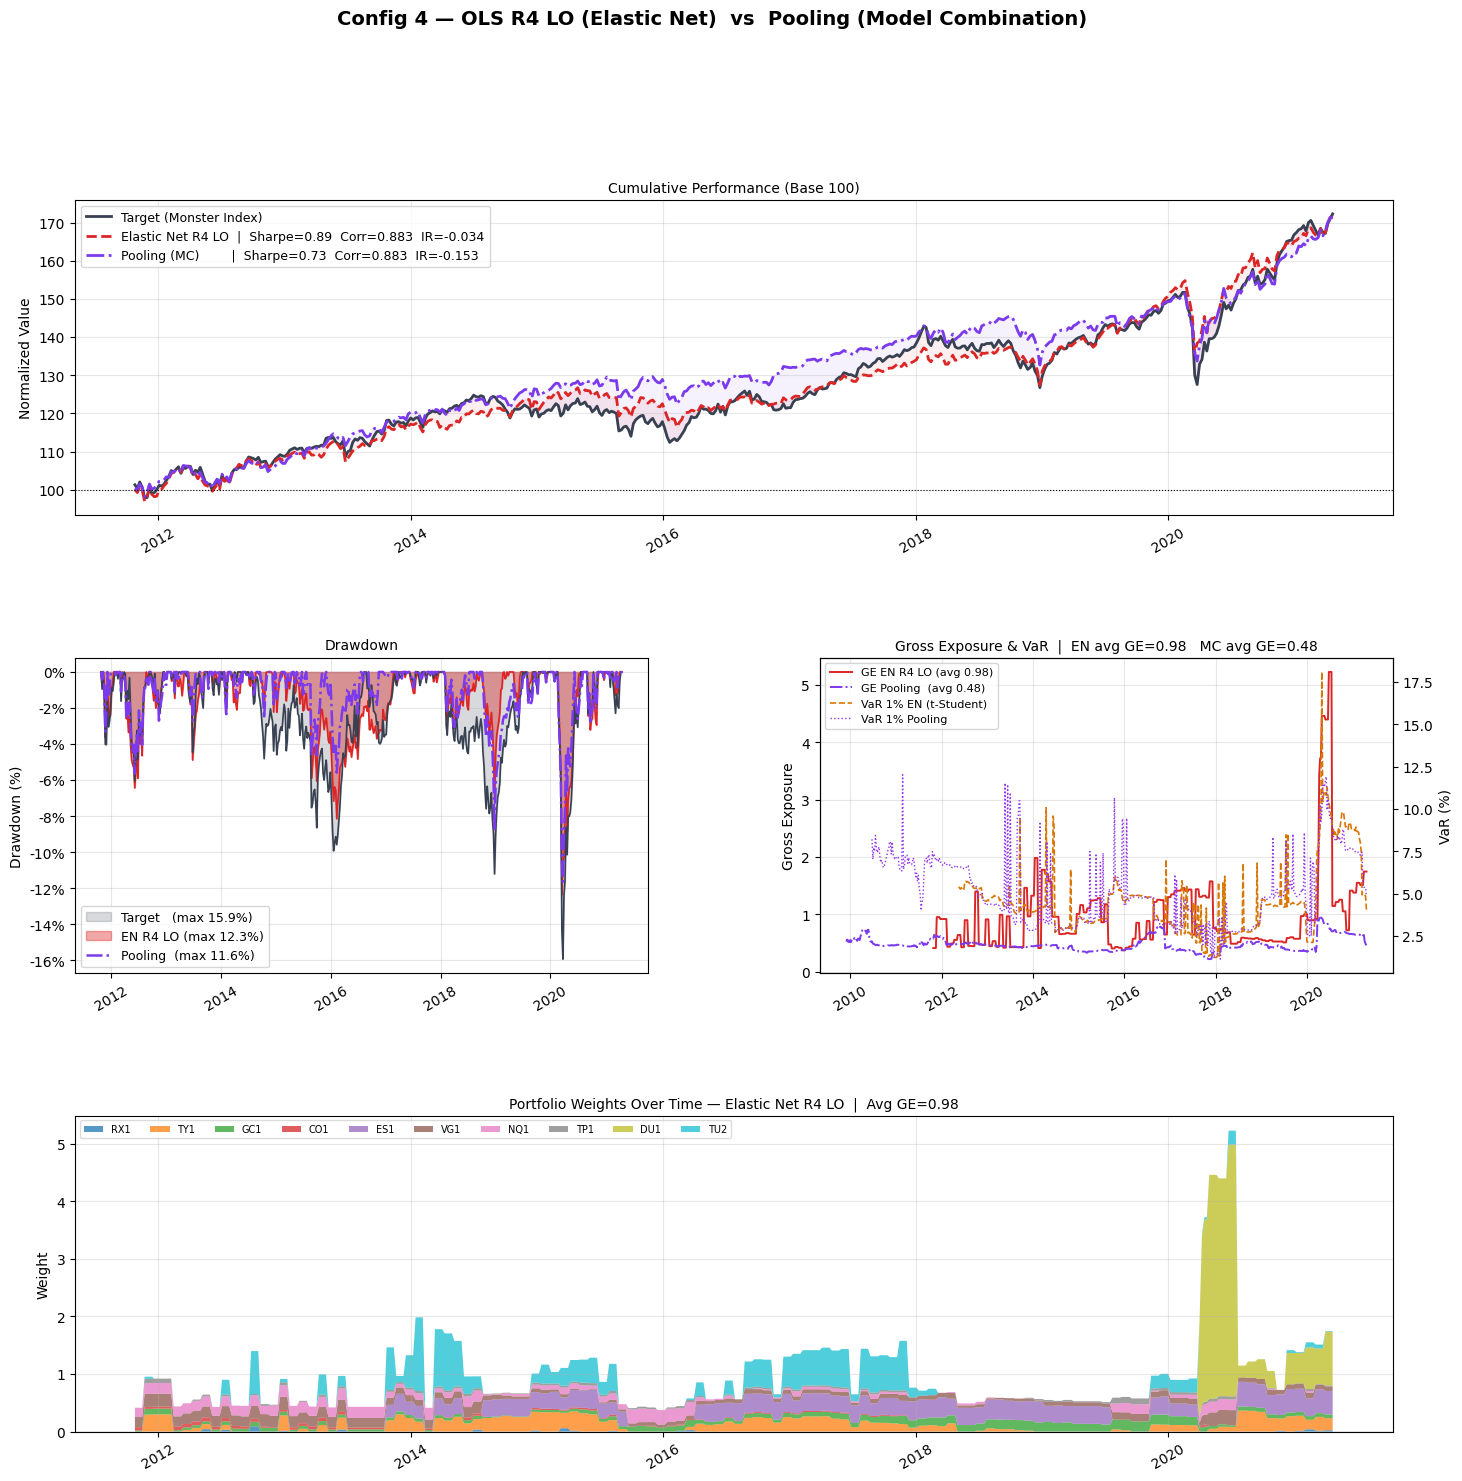


Performance Comparison — Elastic Net Conf 4 vs Pooling:


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
EN R4 LO,-0.034,3.53,0.883,0.89,5.87,6.56,12.3,0.98,2.61,2.39e-05
Pooling MC,-0.153,3.76,0.883,0.73,4.91,6.74,11.6,0.48,0.69,2.72e-05


In [17]:
# ═══════════════════════════════════════════════════════════════════════════════
# Combined Dashboard — Elastic Net Conf 4 (OLS R4 LO) + Pooling (MC)
# ═══════════════════════════════════════════════════════════════════════════════
from IPython.display import display

# ── 1. Extract Elastic Net Conf 4 results ───────────────────────────────────
res4       = all_results[3]          # OLS R4 LO = indice 3
y_pred_en4 = res4["y_pred"]
y_test_en4 = res4["y_test"]
ge_en4     = res4["ge"]
var_en4    = res4["var"]
wdf_en4    = res4["weights_df"]
m4         = res4["metrics"]

# ── 2. Pooling metrics (same function as EN) ────────────────────────────────
m_mc = compute_metrics(y_pred_MC, y_test_MC, weights_MC)

# ── 3. Rolling Student-t VaR for Pooling ────────────────────────────────────
var_mc_vals = []
for i in range(len(y_pred_MC)):
    if i >= 30:
        lbk  = min(52, i)
        hist = y_pred_MC.values[max(0, i - lbk) : i]
        hist = hist[np.isfinite(hist)]
        ev   = var_student_t(hist, var_confidence, var_horizon) if len(hist) >= 10 else np.nan
    else:
        ev = np.nan
    var_mc_vals.append(ev)
var_mc = pd.Series(var_mc_vals, index=y_pred_MC.index, name="VaR_MC")

# ── 4. Alignment — start from when EN4 has its first result ─────────────────
start_date = y_pred_en4.index[0]

y_pred_MC_p = y_pred_MC.loc[start_date:]
y_test_MC_p = y_test_MC.loc[start_date:]
ge_MC_p     = ge_MC.loc[start_date:]
var_mc_p    = var_mc.loc[start_date:]

# ── 5. Cumulative series and drawdown (all start from start_date) ───────────
cum_tgt_en4 = (1 + y_test_en4).cumprod() * 100
cum_rep_en4 = (1 + y_pred_en4).cumprod() * 100
cum_tgt_mc  = (1 + y_test_MC_p).cumprod() * 100
cum_rep_mc  = (1 + y_pred_MC_p).cumprod() * 100

dd_r_en4 = 1 - (1 + y_pred_en4).cumprod() / (1 + y_pred_en4).cumprod().cummax()
dd_t_en4 = 1 - (1 + y_test_en4).cumprod() / (1 + y_test_en4).cumprod().cummax()
dd_r_mc  = 1 - (1 + y_pred_MC_p).cumprod() / (1 + y_pred_MC_p).cumprod().cummax()

# ── 5. Colori ────────────────────────────────────────────────────────────────
C_EN4 = "#DC2626"   # rosso  (stesso di PALETTE[3])
C_MC  = "#7C3AED"   # viola  (pooling)
C_TGT = "#374151"   # grigio scuro (target)

# ── 6. Figure — same 3×2 structure as the individual dashboard ──────────────
fig = plt.figure(figsize=(17, 16))
fig.suptitle(
    "Config 4 — OLS R4 LO (Elastic Net)  vs  Pooling (Model Combination)",
    fontsize=14, fontweight="bold", y=0.999
)
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.30)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])
ax4 = fig.add_subplot(gs[2, :])

fmt = mdates.DateFormatter("%Y")
loc = mdates.YearLocator(2)

# ── Panel 1 — Cumulative performance ────────────────────────────────────────
ax1.plot(cum_tgt_en4.index, cum_tgt_en4.values, color=C_TGT, lw=2.0,
         label="Target (Monster Index)")
ax1.plot(cum_rep_en4.index, cum_rep_en4.values, color=C_EN4, lw=2.0, ls="--",
         label=(f"Elastic Net R4 LO  |  "
                f"Sharpe={m4['Sharpe_R']:.2f}  Corr={m4['Corr']:.3f}  IR={m4['IR']:.3f}"))
ax1.plot(cum_rep_mc.index, cum_rep_mc.values, color=C_MC, lw=2.0, ls="-.",
         label=(f"Pooling (MC)        |  "
                f"Sharpe={m_mc['Sharpe_R']:.2f}  Corr={m_mc['Corr']:.3f}  IR={m_mc['IR']:.3f}"))
ax1.fill_between(cum_tgt_en4.index, cum_tgt_en4.values, cum_rep_en4.values,
                 alpha=0.07, color=C_EN4)
# align pooling fill to the corresponding target index
common_mc_tgt = cum_tgt_mc.index.intersection(cum_rep_mc.index)
ax1.fill_between(common_mc_tgt,
                 cum_tgt_mc.loc[common_mc_tgt].values,
                 cum_rep_mc.loc[common_mc_tgt].values,
                 alpha=0.07, color=C_MC)
ax1.axhline(100, color="black", lw=0.8, ls=":")
ax1.set_title("Cumulative Performance (Base 100)", fontsize=10)
ax1.set_ylabel("Normalized Value")
ax1.legend(fontsize=9)
ax1.xaxis.set_major_formatter(fmt); ax1.xaxis.set_major_locator(loc)
ax1.grid(True, alpha=0.3); ax1.tick_params(axis="x", rotation=30)

# ── Panel 2 — Drawdown ───────────────────────────────────────────────────────
ax2.fill_between(dd_t_en4.index, -dd_t_en4 * 100, 0,
                 color=C_TGT, alpha=0.20,
                 label=f"Target   (max {m4['MaxDD_T']*100:.1f}%)")
ax2.fill_between(dd_r_en4.index, -dd_r_en4 * 100, 0,
                 color=C_EN4, alpha=0.40,
                 label=f"EN R4 LO (max {m4['MaxDD_R']*100:.1f}%)")
ax2.plot(dd_r_en4.index, -dd_r_en4 * 100, color=C_EN4, lw=1.2)
ax2.plot(dd_t_en4.index, -dd_t_en4 * 100, color=C_TGT, lw=1.2)
ax2.plot(dd_r_mc.index, -dd_r_mc * 100, color=C_MC, lw=1.8, ls="-.",
         label=f"Pooling  (max {m_mc['MaxDD_R']*100:.1f}%)")
ax2.set_title("Drawdown", fontsize=10)
ax2.set_ylabel("Drawdown (%)")
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(fmt); ax2.xaxis.set_major_locator(loc)
ax2.grid(True, alpha=0.3); ax2.tick_params(axis="x", rotation=30)

# ── Panel 3 — Gross Exposure & VaR ──────────────────────────────────────────
ax3b = ax3.twinx()
ax3.plot(ge_en4.index, ge_en4.values, color=C_EN4, lw=1.4,
         label=f"GE EN R4 LO (avg {ge_en4.mean():.2f})")
ax3.plot(ge_MC.index, ge_MC.values, color=C_MC, lw=1.4, ls="-.",
         label=f"GE Pooling  (avg {ge_MC.mean():.2f})")
ax3b.plot(var_en4.index, var_en4.values * 100, color="#D97706",
          lw=1.2, ls="--", label="VaR 1% EN (t-Student)")
ax3b.plot(var_mc.index, var_mc.values * 100, color="#9333EA",
          lw=1.0, ls=":", label="VaR 1% Pooling")
ax3.set_title(
    f"Gross Exposure & VaR  |  "
    f"EN avg GE={ge_en4.mean():.2f}   MC avg GE={ge_MC.mean():.2f}",
    fontsize=10
)
ax3.set_ylabel("Gross Exposure")
ax3b.set_ylabel("VaR (%)")
lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3b.get_legend_handles_labels()
ax3.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
ax3.xaxis.set_major_formatter(fmt); ax3.xaxis.set_major_locator(loc)
ax3.grid(True, alpha=0.3); ax3.tick_params(axis="x", rotation=30)

# ── Panel 4 — Elastic Net R4 LO weights (stacked area) ─────────────────────
pos_w    = wdf_en4.clip(lower=0)
neg_w    = wdf_en4.clip(upper=0)
colors_w = plt.cm.tab10(np.linspace(0, 1, len(wdf_en4.columns)))
ax4.stackplot(wdf_en4.index, pos_w.T.values,
              labels=wdf_en4.columns.tolist(), colors=colors_w, alpha=0.75)
ax4.stackplot(wdf_en4.index, neg_w.T.values, colors=colors_w, alpha=0.75)
ax4.axhline(0, color="black", lw=0.8)
ax4.set_title(
    f"Portfolio Weights Over Time — Elastic Net R4 LO  |  Avg GE={ge_en4.mean():.2f}",
    fontsize=10
)
ax4.set_ylabel("Weight")
ax4.legend(loc="upper left", fontsize=7, ncol=len(wdf_en4.columns),
           bbox_to_anchor=(0, 1.0), framealpha=0.7)
ax4.xaxis.set_major_formatter(fmt); ax4.xaxis.set_major_locator(loc)
ax4.grid(True, alpha=0.3); ax4.tick_params(axis="x", rotation=30)

plt.savefig("dashboard_en4_vs_pooling.png", dpi=120, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════════
# Metrics table — same format as the EN loop
# ═══════════════════════════════════════════════════════════════════════════════
rows = []
for label_t, mt, ge_s in [
    ("EN R4 LO",   m4,    ge_en4),
    ("Pooling MC", m_mc,  ge_MC),
]:
    rows.append({
        "Config":      label_t,
        "IR":          round(mt["IR"],  3),
        "TEV (%)":     round(mt["TEV"] * 100, 2),
        "Corr":        round(mt["Corr"], 3),
        "Sharpe_R":    round(mt["Sharpe_R"], 2),
        "Ret_R (%)":   round(mt["Ret_R"] * 100, 2),
        "Vol_R (%)":   round(mt["Vol_R"] * 100, 2),
        "MaxDD_R (%)": round(mt["MaxDD_R"] * 100, 1),
        "AvgGE":       round(float(ge_s.mean()), 2),
        "AvgTO":       round(mt["AvgTO"], 2),
        "MSE":         f"{mt['MSE']:.2e}",
    })

tbl = pd.DataFrame(rows).set_index("Config")
print("\nPerformance Comparison — Elastic Net Conf 4 vs Pooling:")
display(tbl)

The model combination approach achieves identical correlation (0.883) but higher TEV (3.76% vs 3.53%), worse IR (−0.153 vs −0.034) and lower Sharpe (0.73 vs 0.89). While Pooling MC benefits from significantly lower gross exposure (0.48 vs 0.98) and near-zero turnover (0.69 vs 2.61), these implementation advantages do not compensate for the weaker risk-adjusted return. Given the negligible gains in tracking and the deterioration in all return-based metrics, the added complexity of the combination approach is not justified under Occam's razor. EN R4 LO remains the preferred specification.

## The Soft Markov Switching Elastic Net

Having established EN R4 LO as our benchmark, we now turn to a more sophisticated regime-aware extension: the Soft Markov Switching Elastic Net (MS-EN), which is fully documented in the main notebook as it was selected as the final model. 

# Kalman Filter Replication

For the Kalman filter we started from a base version that is presented here. This version is considered a failed attempt because, when compared with the regime-aware Kalman filter, the latter performed significantly better.


## Bridge

In [18]:
# Reuse X, y already built in the EN section above
KF_ROLLING_WINDOW   = 104
KF_MAX_LEVERAGE     = 2.0
KF_TURNOVER_THR     = 0.05
KF_TRANSACTION_COST = 0.0004

X_all  = X.values.astype(float)
y_all  = y.values.astype(float)
Date   = X.index.to_numpy()
T, m   = X_all.shape

obs_train   = y_all[:KF_ROLLING_WINDOW]
X_train     = X_all[:KF_ROLLING_WINDOW]
futures_names = list(X.columns)

print(f"T={T}, m={m}, training window={KF_ROLLING_WINDOW} weeks")

T=704, m=10, training window=104 weeks


## Helper Function

In [19]:
def run_kalman(X_all, y_all, q_noise, rolling_window,
               max_leverage=KF_MAX_LEVERAGE, turnover_thr=KF_TURNOVER_THR,
               transaction_cost_rate=KF_TRANSACTION_COST):
    """
    Basic Kalman filter with constant process-noise variance q_noise.
    At each step the filter runs over the rolling window, then produces
    one out-of-sample return.
    """
    T, m = X_all.shape; b_prev = np.zeros(m)
    b_list, r_list, ge_list, tc_list = [], [], [], []
    for i in range(T - rolling_window - 1):
        H = X_all[i:i+rolling_window]; y_meas = y_all[i:i+rolling_window]
        R_s = np.var(y_meas)
        x_pred, P = np.zeros(m), np.eye(m)
        for t in range(rolling_window):
            h = H[t]; S_t = h @ P @ h + R_s
            K = (P @ h) / max(S_t, 1e-300)
            x_pred = x_pred + (y_meas[t] - h @ x_pred) * K
            P = (np.eye(m) - np.outer(K, h)) @ P + np.eye(m) * q_noise
        b_new = x_pred.copy()
        gl = np.abs(b_new).sum()
        if gl > max_leverage: b_new *= max_leverage / gl
        proposed = np.abs(b_new - b_prev).sum()
        if b_list and proposed < turnover_thr:
            b_new = b_prev.copy(); turnover = 0.0
        else:
            turnover = proposed
        tc_cost = transaction_cost_rate * turnover
        b_prev = b_new.copy()
        ge_list.append(np.abs(b_new).sum()); b_list.append(b_new.copy())
        tc_list.append(tc_cost); r_list.append(X_all[i+rolling_window] @ b_new - tc_cost)
    return np.array(r_list), np.array(b_list), np.array(ge_list), np.array(tc_list)


## Kalman Base (constant Q)

In [20]:
q_constant = np.mean(np.var(X_all[:KF_ROLLING_WINDOW], axis=0))
print(f"[Base] Q = {q_constant:.2e}")

r_base, b_base, ge_base, tc_base = run_kalman(
    X_all, y_all, q_constant, KF_ROLLING_WINDOW)
print(f"[Base] OOS steps: {len(r_base)}")


[Base] Q = 1.22e-03
[Base] OOS steps: 599


## Results & Performance Metrics

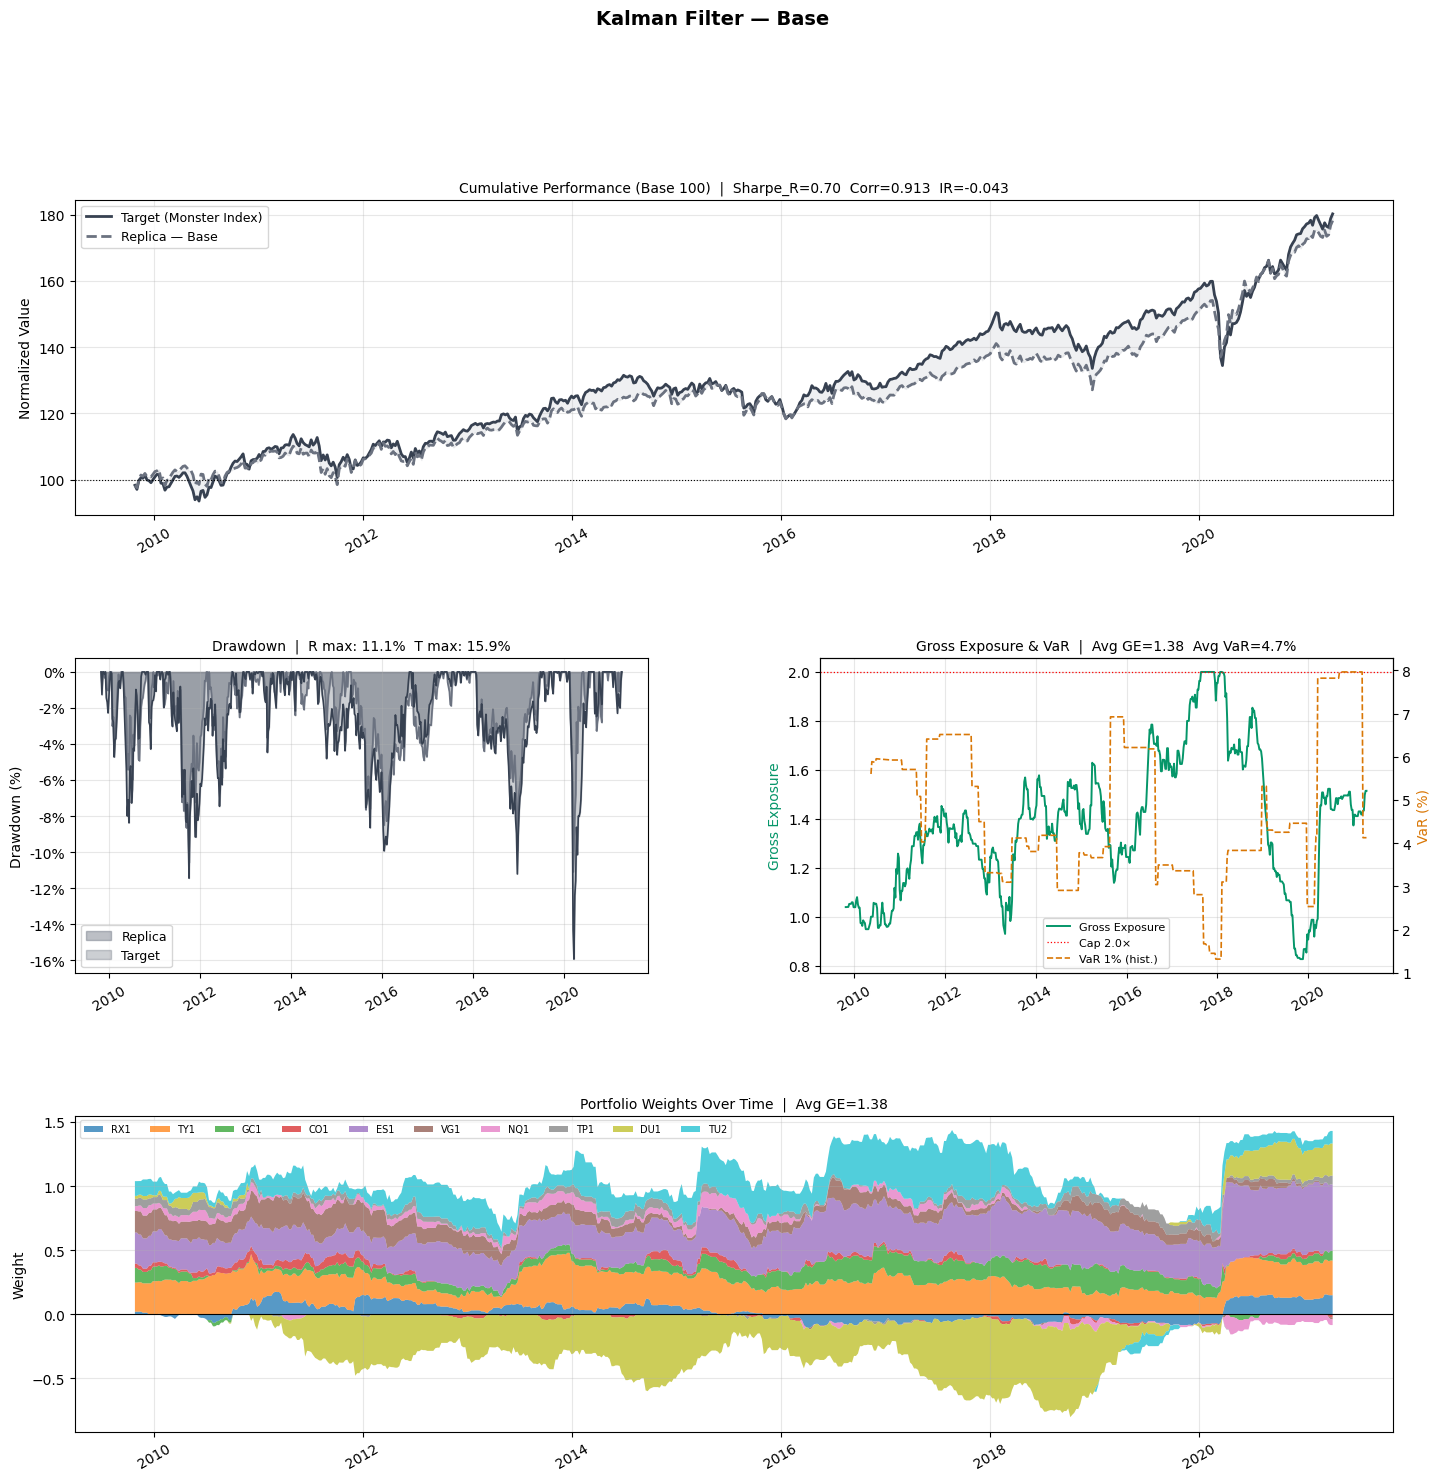

Kalman Base — Performance:


,IR,TEV (%),Corr,Sharpe_R,Ret_R (%),Vol_R (%),MaxDD_R (%),AvgGE,AvgTO,MSE
Config,,,,,,,,,,
Kalman Base,-0.043,3.29,0.913,0.7,5.3,7.53,11.1,1.38,2.13,2.08e-05


In [21]:
date_oos = Date[KF_ROLLING_WINDOW : KF_ROLLING_WINDOW + len(r_base)]
target_oos = y_all[KF_ROLLING_WINDOW : KF_ROLLING_WINDOW + len(r_base)]

LBL      = "Base"
C_KF     = "#6B7280"
date_idx = pd.DatetimeIndex(date_oos)

fmt_kf   = mdates.DateFormatter("%Y")
loc_kf   = mdates.YearLocator(2)

y_pred_kf = pd.Series(r_base,     index=date_idx, name="Replica")
y_test_kf = pd.Series(target_oos, index=date_idx, name="Target")

# Rolling historical VaR
r_base_s = pd.Series(r_base, index=date_idx)
var_kf   = r_base_s.rolling(52, min_periods=30).quantile(0.01).abs() * np.sqrt(4)

fig = plt.figure(figsize=(17, 16))
fig.suptitle("Kalman Filter — Base", fontsize=14, fontweight="bold", y=0.999)
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.30)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])
ax4 = fig.add_subplot(gs[2, :])

# Panel 1 — cumulative performance
cum_tgt_kf = (1 + target_oos).cumprod() * 100
cum_rep_kf = (1 + r_base).cumprod() * 100
sharpe_kf  = np.mean(r_base) * 52 / (np.std(r_base) * np.sqrt(52))
corr_kf    = np.corrcoef(target_oos, r_base)[0, 1]
te_kf      = r_base - target_oos
ir_kf      = np.mean(te_kf) / np.std(te_kf) * np.sqrt(52)

ax1.plot(date_idx, cum_tgt_kf, color="#374151", lw=2.0, label="Target (Monster Index)")
ax1.plot(date_idx, cum_rep_kf, color=C_KF,     lw=2.0, ls="--", label=f"Replica — {LBL}")
ax1.fill_between(date_idx, cum_tgt_kf, cum_rep_kf, alpha=0.10, color=C_KF)
ax1.axhline(100, color="black", lw=0.8, ls=":")
ax1.set_title(
    f"Cumulative Performance (Base 100)  |  "
    f"Sharpe_R={sharpe_kf:.2f}  Corr={corr_kf:.3f}  IR={ir_kf:.3f}",
    fontsize=10
)
ax1.set_ylabel("Normalized Value"); ax1.legend(fontsize=9)
ax1.xaxis.set_major_formatter(fmt_kf); ax1.xaxis.set_major_locator(loc_kf)
ax1.grid(True, alpha=0.3); ax1.tick_params(axis="x", rotation=30)

# Panel 2 — drawdown
cum_tgt_s  = pd.Series(cum_tgt_kf, index=date_idx)
cum_rep_s  = pd.Series(cum_rep_kf, index=date_idx)
dd_tgt_kf  = 1 - cum_tgt_s / cum_tgt_s.cummax()
dd_rep_kf  = 1 - cum_rep_s / cum_rep_s.cummax()
mdd_rep_kf = dd_rep_kf.max(); mdd_tgt_kf = dd_tgt_kf.max()

ax2.fill_between(date_idx, -dd_rep_kf*100, 0, color=C_KF,     alpha=0.45, label="Replica")
ax2.fill_between(date_idx, -dd_tgt_kf*100, 0, color="#374151", alpha=0.25, label="Target")
ax2.plot(date_idx, -dd_rep_kf*100, color=C_KF,     lw=1.2)
ax2.plot(date_idx, -dd_tgt_kf*100, color="#374151", lw=1.2)
ax2.set_title(f"Drawdown  |  R max: {mdd_rep_kf*100:.1f}%  T max: {mdd_tgt_kf*100:.1f}%",
              fontsize=10)
ax2.set_ylabel("Drawdown (%)")
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(fmt_kf); ax2.xaxis.set_major_locator(loc_kf)
ax2.grid(True, alpha=0.3); ax2.tick_params(axis="x", rotation=30)

# Panel 3 — Gross Exposure + VaR
ax3b = ax3.twinx()
ge_s_kf = pd.Series(ge_base, index=date_idx)
ax3.plot(date_idx, ge_s_kf.values,  color="#059669", lw=1.4, label="Gross Exposure")
ax3b.plot(date_idx, var_kf.values*100, color="#D97706", lw=1.2, ls="--",
          label="VaR 1% (hist.)")
ax3.axhline(KF_MAX_LEVERAGE, color="red", lw=0.9, ls=":", label=f"Cap {KF_MAX_LEVERAGE}×")
ax3.set_title(
    f"Gross Exposure & VaR  |  Avg GE={ge_s_kf.mean():.2f}  "
    f"Avg VaR={var_kf.mean()*100:.1f}%",
    fontsize=10
)
ax3.set_ylabel("Gross Exposure", color="#059669")
ax3b.set_ylabel("VaR (%)", color="#D97706")
lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3b.get_legend_handles_labels()
ax3.legend(lines1+lines2, labels1+labels2, fontsize=8)
ax3.xaxis.set_major_formatter(fmt_kf); ax3.xaxis.set_major_locator(loc_kf)
ax3.grid(True, alpha=0.3); ax3.tick_params(axis="x", rotation=30)

# Panel 4 — stacked area weights
b_df     = pd.DataFrame(b_base, index=date_idx, columns=futures_names)
colors_w = plt.cm.tab10(np.linspace(0, 1, len(futures_names)))
ax4.stackplot(date_idx, b_df.clip(lower=0).T.values,
              labels=futures_names, colors=colors_w, alpha=0.75)
ax4.stackplot(date_idx, b_df.clip(upper=0).T.values,
              colors=colors_w, alpha=0.75)
ax4.axhline(0, color="black", lw=0.8)
ax4.set_title(f"Portfolio Weights Over Time  |  Avg GE={ge_s_kf.mean():.2f}", fontsize=10)
ax4.set_ylabel("Weight")
ax4.legend(loc="upper left", fontsize=7, ncol=len(futures_names),
           bbox_to_anchor=(0, 1.0), framealpha=0.7)
ax4.xaxis.set_major_formatter(fmt_kf); ax4.xaxis.set_major_locator(loc_kf)
ax4.grid(True, alpha=0.3); ax4.tick_params(axis="x", rotation=30)

plt.savefig("kalman_base.png", dpi=130, bbox_inches="tight")
plt.show()

m_kf = compute_metrics(y_pred_kf, y_test_kf, b_base)

rows_kf = [{
    "Config":      "Kalman Base",
    "IR":          round(m_kf["IR"],  3),
    "TEV (%)":     round(m_kf["TEV"] * 100, 2),
    "Corr":        round(m_kf["Corr"], 3),
    "Sharpe_R":    round(m_kf["Sharpe_R"], 2),
    "Ret_R (%)":   round(m_kf["Ret_R"] * 100, 2),
    "Vol_R (%)":   round(m_kf["Vol_R"] * 100, 2),
    "MaxDD_R (%)": round(m_kf["MaxDD_R"] * 100, 1),
    "AvgGE":       round(float(ge_base.mean()), 2),
    "AvgTO":       round(m_kf["AvgTO"], 2),
    "MSE":         f"{m_kf['MSE']:.2e}",
}]

tbl_kf = pd.DataFrame(rows_kf).set_index("Config")
print("Kalman Base — Performance:")
display(tbl_kf)




The base Kalman filter already delivers strong tracking performance, achieving the
highest correlation across all models tested so far  and the lowest TEV.
However, its IR remains negative (-0.043) and its Sharpe ratio (0.70) falls below
EN R4 LO (0.85) and MS-EN (0.826), indicating that the improved tracking comes at
the cost of weaker return generation. This confirms that the base Kalman filter,
while effective as a pure replication tool, lacks the adaptability needed to match
the risk-adjusted performance of the regime-aware models. It therefore served as the
starting point for the regime-aware Kalman filter developed in the main notebook.

---
# LSTM — Sequential Replication Model

**Reference**: This cell extends the notebook's rolling replication framework with a
Long Short-Term Memory (LSTM) network. The design mirrors the Elastic Net section:
same risk controls (VaR constraint, turnover gate, transaction costs), same performance
metrics, and the same rolling/expanding-window structure.

## Motivation

The Elastic Net and Kalman Filter both assume **linear, time-invariant** (or slowly
drifting) relationships between futures returns and the target. In practice:

- Factor loadings are **regime-dependent** (already addressed via the Bayesian HMM).
- Returns may exhibit **non-linear cross-asset interactions** that a linear regression
  model cannot capture — e.g. the asymmetric equity-bond correlation in crisis periods.
- There may be **sequential dependencies** in the weight-update process that a
  recurrent architecture can exploit.

An LSTM learns a **hidden state** $h_t$ that summarises the history of inputs. At each
step it predicts the target return as:

$$\hat{r}_t = W_o \cdot h_t + b_o$$

where $h_t$ evolves through gated updates controlled by the input gate $i$, forget gate
$f$, and output gate $o$:

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f) \\
i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i) \\
\tilde{c}_t &= \tanh(W_c [h_{t-1}, x_t] + b_c) \\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \\
o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o) \\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

The forget gate $f_t$ is the LSTM's equivalent of the Kalman gain: it decides how much
of the previous hidden state to retain. Unlike the Kalman filter (which uses a linear
Gaussian model to compute the gain analytically), the LSTM learns the gating function
from data.

## Implementation choices

| Choice | Value | Rationale |
|--------|-------|-----------|
| **Lookback window** | 8 weeks | Short enough to avoid overfitting on 700 observations; captures roughly one rebalancing cycle |
| **Hidden units** | 32 | Small network reduces overfitting; comparable to EN's ~10 non-zero coefficients |
| **Dropout** | 0.2 | Recurrent + input dropout; standard regularisation for financial LSTMs |
| **Training window** | 208 weeks (4 years) | Same maximum window as EN grid |
| **Rebalancing** | Every 12 weeks | Identical to `REBAL_FREQ` in the EN section |
| **Epochs / early stop** | max 100 / patience 10 | Prevents over-training on the rolling window |
| **Regime weighting** | `compute_sample_weights` | Reuses the same Bayesian HMM weights as EN |
| **Risk controls** | Turnover gate + VaR | Identical thresholds to EN section |

In [22]:
# ── Dependencies ──────────────────────────────────────────────────────────────
# All standard imports are already loaded from the main notebook.
# We only add the Keras/TensorFlow imports here.

import warnings
warnings.filterwarnings('ignore')

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # suppress TF info/warnings

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Reproducibility
LSTM_SEED = 42
tf.random.set_seed(LSTM_SEED)
np.random.seed(LSTM_SEED)

print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")

TensorFlow version : 2.21.0
Keras version      : 3.14.1


### Hyper-parameters

In [23]:
# ── LSTM hyper-parameters ─────────────────────────────────────────────────────

# ── Rebalancing frequency ─────────────────────────────────────────────────────
REBAL_FREQ = 4   #weeks

#Hyperparameters
TURNOVER_THRESHOLD = 0.03   # two-way turnover gate threshold
MAX_LEVERAGE       = 2.0    # gross leverage cap (used if USE_GE_CAP = True)
TRANSACTION_COST   = 0.0004 # 4 bps round-trip per unit of one-way turnover

var_confidence    = 0.01   # 1% confidence level
var_horizon       = 4      # 4-week horizon, consistent with REBAL_FREQ
max_var_threshold = 0.20   # maximum allowed VaR (20%)

LSTM_LOOKBACK      = 8      # number of lagged weeks fed as a sequence to the LSTM
LSTM_HIDDEN        = 32     # hidden units in the LSTM layer
LSTM_DROPOUT       = 0.20   # input dropout rate
LSTM_REC_DROPOUT   = 0.20   # recurrent dropout rate
LSTM_EPOCHS        = 100    # maximum training epochs per rolling window
LSTM_PATIENCE      = 10     # early-stopping patience (epochs without improvement)
LSTM_BATCH         = 16     # mini-batch size
LSTM_LR            = 1e-3   # Adam learning rate
LSTM_TRAIN_WINDOW  = 208    # training window (weeks) — same as EN max window (4 yrs)
LSTM_REBAL_FREQ    = REBAL_FREQ   # rebalancing frequency — reuse EN constant (12 weeks)
LSTM_VAL_SPLIT     = 0.15   # fraction of training window held out for early-stopping

# Risk-control thresholds — identical to the EN section
LSTM_TURNOVER_THR  = TURNOVER_THRESHOLD   # two-way turnover gate
LSTM_MAX_VAR       = max_var_threshold    # GARCH VaR cap (20%)
LSTM_TC            = TRANSACTION_COST     # 4 bps round-trip per unit turnover

print("LSTM configuration:")
print(f"  Lookback       : {LSTM_LOOKBACK} weeks")
print(f"  Hidden units   : {LSTM_HIDDEN}")
print(f"  Dropout        : {LSTM_DROPOUT} (input) / {LSTM_REC_DROPOUT} (recurrent)")
print(f"  Training window: {LSTM_TRAIN_WINDOW} weeks ({LSTM_TRAIN_WINDOW//52:.0f} years)")
print(f"  Rebal. freq    : every {LSTM_REBAL_FREQ} weeks")
print(f"  Max VaR        : {LSTM_MAX_VAR:.0%}  |  Turnover gate: {LSTM_TURNOVER_THR:.0%}")

LSTM configuration:
  Lookback       : 8 weeks
  Hidden units   : 32
  Dropout        : 0.2 (input) / 0.2 (recurrent)
  Training window: 208 weeks (4 years)
  Rebal. freq    : every 4 weeks
  Max VaR        : 20%  |  Turnover gate: 3%


### Helper functions

In [24]:
# ── Sequence builder ──────────────────────────────────────────────────────────

def build_sequences(X_2d, y_1d, lookback):
    """
    Convert a flat (T, m) feature matrix and (T,) target vector into
    overlapping sequences of length `lookback`.

    Returns
    -------
    X_seq : ndarray (T-lookback, lookback, m)   — input sequences
    y_seq : ndarray (T-lookback,)               — targets (at end of each sequence)

    Leakage note: y_seq[t] = y_1d[t + lookback], i.e. the return AFTER the
    sequence ends.  No future data enters the sequence.
    """
    T, m = X_2d.shape
    X_seq = np.zeros((T - lookback, lookback, m), dtype=np.float32)
    y_seq = np.zeros( T - lookback,              dtype=np.float32)

    for t in range(T - lookback):
        X_seq[t] = X_2d[t : t + lookback]   # rows t … t+lookback-1
        y_seq[t] = y_1d[t + lookback]        # label is the NEXT return

    return X_seq, y_seq


# ── Model factory ─────────────────────────────────────────────────────────────

def build_lstm_model(n_features, lookback,
                     hidden=LSTM_HIDDEN,
                     dropout=LSTM_DROPOUT,
                     rec_dropout=LSTM_REC_DROPOUT,
                     lr=LSTM_LR):
    """
    Single-layer LSTM regressor.

    Architecture
    ------------
    Input (lookback, n_features)
      └─ LSTM(hidden, dropout=dropout, recurrent_dropout=rec_dropout)
           └─ Dense(16, activation='tanh')   — non-linear feature compression
                └─ Dense(1, activation=None) — scalar return prediction

    We keep the architecture deliberately small:
      - 700 weekly observations is a tiny dataset for a neural network.
      - Depth adds expressiveness but also variance; one LSTM layer is enough
        to capture the sequential dependencies we care about.
      - The second Dense layer adds a mild non-linearity between the LSTM
        hidden state and the output, without dramatically increasing parameter
        count.
    """
    inp  = keras.Input(shape=(lookback, n_features))
    x    = layers.LSTM(
        hidden,
        dropout=dropout,
        recurrent_dropout=rec_dropout,
        return_sequences=False,
        kernel_regularizer=keras.regularizers.l2(1e-4),
        recurrent_regularizer=keras.regularizers.l2(1e-4),
    )(inp)
    x    = layers.Dense(16, activation='tanh',
                        kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    out  = layers.Dense(1)(x)

    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0),
        loss='mse'
    )
    return model


# ── Feature scaler (causal, fitted on training window only) ──────────────────

def scale_features(X_train, X_pred_row):
    """
    Standardise features using training-window statistics only.
    X_pred_row is the single prediction row (1, m) — no leakage.
    """
    mu    = X_train.mean(axis=0, keepdims=True)
    sigma = X_train.std( axis=0, keepdims=True) + 1e-8
    return (X_train - mu) / sigma, (X_pred_row - mu) / sigma


print("LSTM helper functions defined:")
print("  build_sequences   — overlapping sequence construction")
print("  build_lstm_model  — single-layer LSTM regressor")
print("  scale_features    — causal z-score standardisation")

LSTM helper functions defined:
  build_sequences   — overlapping sequence construction
  build_lstm_model  — single-layer LSTM regressor
  scale_features    — causal z-score standardisation


### Rolling LSTM loop

At each rebalancing date the algorithm:

1. **Extracts** the training window `[i - LSTM_TRAIN_WINDOW, i)` and scales it causally.
2. **Applies regime weights** via `compute_sample_weights` (same HMM filter as EN).
3. **Rebuilds and retrains** the LSTM from scratch with early stopping on a held-out
   validation slice at the end of the training window.
4. **Predicts** $\hat{r}_{i}$ using the last `LSTM_LOOKBACK` weeks as input.
5. **Applies risk controls**: turnover gate → VaR constraint → transaction costs.

On non-rebalancing weeks the cached prediction weights are reused (identical to EN).

In [25]:
def online_bayesian_hmm(
    y_all,
    A0,
    mu0,
    sig0,
    rolling_window,
    n_states    = 2,
    kappa_dir   = 10.0,
    kappa_ng    = 5.0,
    a0          = 3.0,
):
    T = len(y_all)

    # ── Initialise Dirichlet prior from Baum-Welch transition matrix ──────────
    alpha_dir = np.maximum(A0, 1e-8) * kappa_dir
    alpha_dir = alpha_dir / alpha_dir.sum(axis=1, keepdims=True) * kappa_dir

    # ── Initialise Normal-Gamma prior from Baum-Welch emission estimates ──────
    ng_m     = mu0.copy()
    ng_kappa = np.full(n_states, kappa_ng)
    ng_a     = np.full(n_states, a0)
    ng_b     = a0 * sig0 ** 2

    # ── Storage ───────────────────────────────────────────────────────────────
    alpha_B   = np.zeros((T, n_states))
    hmm_var_B = np.zeros(T)

    # ── Training block: self-contained forward filter from t=0 ───────────────
    alpha_prev = np.full(n_states, 1.0 / n_states)

    for t in range(rolling_window):
        post_var = ng_b / np.maximum(ng_a - 1, 1e-6)
        pred_var = post_var * (1.0 + 1.0 / ng_kappa)
        pred_std = np.maximum(np.sqrt(pred_var), 1e-300)
        B_t = np.maximum(
            np.array([norm.pdf(y_all[t], ng_m[s], pred_std[s]) for s in range(n_states)]),
            1e-300)
        alpha_upd      = alpha_prev * B_t
        alpha_upd     /= max(alpha_upd.sum(), 1e-300)
        alpha_B[t]     = alpha_upd
        hmm_var_B[t]   = alpha_upd @ pred_var
        alpha_prev     = alpha_upd

    # ── Online filter ─────────────────────────────────────────────────────────
    for t in range(rolling_window, T):
        y_t = y_all[t]

        # Step 1: predictive quantities (before seeing y_t — leakage guard)
        post_var = ng_b / np.maximum(ng_a - 1, 1e-6)
        pred_var = post_var * (1.0 + 1.0 / ng_kappa)
        pred_std = np.maximum(np.sqrt(pred_var), 1e-300)

        A_post       = alpha_dir / np.maximum(alpha_dir.sum(axis=1, keepdims=True), 1e-300)
        alpha_pred   = alpha_prev @ A_post
        hmm_var_B[t] = alpha_pred @ pred_var

        # Step 2: forward filter update
        B_t = np.maximum(
            np.array([norm.pdf(y_t, ng_m[s], pred_std[s]) for s in range(n_states)]),
            1e-300)
        alpha_upd      = alpha_pred * B_t
        alpha_upd     /= max(alpha_upd.sum(), 1e-300)
        alpha_B[t]     = alpha_upd
        gamma_t        = alpha_upd

        # Step 3: Dirichlet update
        xi_t_num   = alpha_prev[:, None] * A_post * B_t[None, :]
        xi_t       = xi_t_num / max(xi_t_num.sum(), 1e-300)
        alpha_dir += xi_t

        # Step 4: Normal-Gamma update
        for s in range(n_states):
            g_s         = gamma_t[s]
            k_old       = ng_kappa[s]
            m_old       = ng_m[s]
            ng_kappa[s] = k_old + g_s
            ng_m[s]     = (k_old * m_old + g_s * y_t) / ng_kappa[s]
            ng_a[s]    += g_s / 2.0
            ng_b[s]    += 0.5 * g_s * (k_old / ng_kappa[s]) * (y_t - m_old) ** 2

        alpha_prev = alpha_upd

    prob_vol_B = alpha_B[:, 1]
    print("[Approach B] Online Bayesian filtering complete.")
    print(f"  Mean P(volatile) over full sample: {prob_vol_B.mean():.4f}")

    return prob_vol_B, alpha_B, hmm_var_B

In [26]:
def baum_welch(obs, n_states=2, max_iter=200, tol=1e-6, seed=42):
    """
    Fit a Gaussian Hidden Markov Model via the Baum-Welch (EM) algorithm.

    A Hidden Markov Model assumes that the observable series (here, portfolio
    log-returns) is generated by a latent Markov chain with S states.  Each
    state s emits observations from a Gaussian N(mu[s], sigma[s]).  The chain
    evolves according to a transition matrix A, where A[i,j] = P(state j at
    t+1 | state i at t).

    Baum-Welch alternates between:
      E-step: compute soft state assignments (gamma) and soft transition
              counts (xi) given current parameters.
      M-step: re-estimate A, mu, sigma as weighted averages over the data,
              using gamma and xi as weights.

    The log-likelihood is guaranteed non-decreasing at each iteration.

    Parameters
    ----------
    obs      : 1-D array of T observations.
    n_states : number of hidden states (default 2: quiet and volatile).
    max_iter : maximum EM iterations.
    tol      : convergence threshold on log-likelihood improvement.
    seed     : random seed for KMeans initialisation.

    Returns
    -------
    dict with keys A, pi, mu, sigma, gamma.
    """
    T  = len(obs)
    sq = obs ** 2

    # --- Initialisation via KMeans on squared observations ---
    # Squared returns proxy for variance.  Clustering them separates the
    # low-variance (quiet) and high-variance (volatile) regimes, giving
    # a better starting point than random assignment and reducing the
    # risk of converging to a degenerate local optimum.
    km  = KMeans(n_clusters=n_states, n_init=10, max_iter=500,
                 random_state=seed).fit(sq.reshape(-1, 1))
    lbl = km.labels_

    mu    = np.array([obs[lbl == s].mean() for s in range(n_states)])
    sigma = np.array([obs[lbl == s].std()  for s in range(n_states)])

    # Enforce label convention: state 0 = quiet (lower sigma),
    # state 1 = volatile (higher sigma).  Consistent labelling across
    # restarts is essential for comparing regime probabilities over time.
    if sigma[0] > sigma[1]:
        mu, sigma = mu[::-1].copy(), sigma[::-1].copy()

    # Start with a mildly persistent transition matrix and a uniform
    # initial distribution.  The diagonal value of 0.95 reflects the
    # prior belief that regimes last on average 20 periods before switching.
    A  = np.array([[0.95, 0.05], [0.05, 0.95]], dtype=float)
    pi = np.full(n_states, 1.0 / n_states)
    ll_prev = -np.inf

    for itr in range(max_iter):

        # -----------------------------------------------------------------
        # E-step part 1: emission probabilities
        # B[t, s] = p(obs[t] | state s) under the current Gaussian N(mu[s], sigma[s]).
        # Floored at 1e-300 to prevent exact zeros from propagating through
        # the forward-backward recursion.
        # -----------------------------------------------------------------
        B = np.column_stack(
            [norm.pdf(obs, mu[s], max(sigma[s], 1e-300)) for s in range(n_states)]
        )
        B = np.maximum(B, 1e-300)

        # -----------------------------------------------------------------
        # E-step part 2: forward pass (scaled alpha)
        # alpha[t, s] = P(state s at t | obs[0..t]), computed recursively.
        # Scaling by c[t] = sum_s(alpha[t, s]) avoids numerical underflow
        # over long sequences; log(c) accumulates into the log-likelihood.
        # -----------------------------------------------------------------
        alpha, c = np.zeros((T, n_states)), np.zeros(T)
        alpha[0] = pi * B[0]
        c[0]     = max(alpha[0].sum(), 1e-300)
        alpha[0] /= c[0]
        for t in range(1, T):
            # Predict: propagate the previous distribution through A.
            # Update: weight by the emission likelihood of the new observation.
            alpha[t] = (alpha[t-1] @ A) * B[t]
            c[t]     = max(alpha[t].sum(), 1e-300)
            alpha[t] /= c[t]

        # -----------------------------------------------------------------
        # E-step part 3: backward pass (scaled beta)
        # beta[t, s] = P(obs[t+1..T] | state s at t), computed right-to-left.
        # Dividing by c[t+1] (the forward scaling constant) is equivalent
        # to using the same scale as alpha, which cancels in gamma = alpha * beta.
        # -----------------------------------------------------------------
        beta = np.ones((T, n_states))
        for t in range(T-2, -1, -1):
            beta[t] = (A @ (B[t+1] * beta[t+1])) / max(c[t+1], 1e-300)

        # -----------------------------------------------------------------
        # E-step part 4: smoothed state probabilities (gamma)
        # gamma[t, s] = P(state s at t | all observations).
        # This is the "full-information" soft assignment: unlike alpha (which
        # uses only past data), gamma also incorporates future observations
        # via beta.  It is used only inside the training window (Baum-Welch);
        # the live filter uses alpha only to avoid look-ahead.
        # -----------------------------------------------------------------
        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)

        # -----------------------------------------------------------------
        # E-step part 5: joint transition probabilities (xi)
        # xi[t, i, j] = P(state i at t, state j at t+1 | all observations).
        # These are the soft transition counts used to re-estimate A.
        # -----------------------------------------------------------------
        xi = np.zeros((T-1, n_states, n_states))
        for t in range(T-1):
            num   = alpha[t][:, None] * A * (B[t+1] * beta[t+1])[None, :]
            xi[t] = num / max(num.sum(), 1e-300)

        # Scaled log-likelihood: sum of log normalisation constants.
        ll = np.log(c).sum()

        # -----------------------------------------------------------------
        # M-step: update parameters as responsibility-weighted statistics.
        # pi  <- initial state probability (gamma at t=0).
        # A   <- normalised soft transition counts (sum of xi over time).
        # mu  <- weighted mean of observations, weight = gamma[t, s].
        # sigma <- weighted standard deviation, same weighting.
        # -----------------------------------------------------------------
        pi = gamma[0]
        for i in range(n_states):
            rs   = max(xi[:, i, :].sum(), 1e-300)
            A[i] = xi[:, i, :].sum(axis=0) / rs
            A[i] /= A[i].sum()
        for s in range(n_states):
            gs       = max(gamma[:, s].sum(), 1e-300)
            mu[s]    = (gamma[:, s] * obs).sum() / gs
            sigma[s] = max(np.sqrt((gamma[:, s] * (obs - mu[s])**2).sum() / gs), 1e-6)

        # Re-apply label convention after each M-step in case states swapped.
        if sigma[0] > sigma[1]:
            mu, sigma = mu[::-1].copy(), sigma[::-1].copy()
            gamma     = gamma[:, ::-1].copy()
            A         = A[::-1, ::-1].copy()
            pi        = pi[::-1].copy()

        if abs(ll - ll_prev) < tol:
            print(f"    Baum-Welch converged at iteration {itr+1}")
            break
        ll_prev = ll

    return dict(A=A, pi=pi, mu=mu, sigma=sigma, gamma=gamma)

In [27]:
# ── Adaptive parameters ──────────────────────────────────────────────────────
USE_ADAPTIVE_REGIME  = True
ADAPTIVE_HALF_LIVES  = [4, 26, 52]   # fast / medium / slow decay
ADAPTIVE_ALPHA       = 1.0
HALF_LIFE_MIN        = 4
HALF_LIFE_MAX        = 78

# ── Regime filter parameters ──────────────────────────────────────────────────
USE_HMM_REGIME   = True
HMM_VOL_WINDOW   = 13     # rolling vol window fed to the Bayesian filter
HMM_MIN_OBS      = 20     # minimum observations before using the regime filter
REGIME_WEIGHT    = 0.5    # blend weight: 0 = Adaptive only, 1 = regime only
TRANSITION_STAY  = 0.95   # regime persistence: P(bull->bull) = P(bear->bear)
BEAR_THRESHOLD   = 0.5    # posterior threshold to classify bear
VOTE_WINDOW      = 4      # majority vote over last N weeks

# ── EWM parameters (fallback) ─────────────────────────────────────────────────
USE_EWM   = True
EWM_DECAY = 0.97

# ── Bridge ────────────────────────────────────────────────────────
y_all          = y.values.astype(float)
T              = len(y_all)

rolling_windows = [104, 156, 208]   # 2, 3, 4 years
obs_train      = y_all[:rolling_windows[0]]

# ── Baum-Welch ────────────────────────────────────────────────────
hmm0 = baum_welch(obs_train)
A0   = hmm0["A"].copy()
pi0  = hmm0["pi"].copy()
mu0  = hmm0["mu"].copy()
sig0 = hmm0["sigma"].copy()

prob_vol_B, alpha_B, hmm_var_B = online_bayesian_hmm(
    y_all          = y_all,
    A0             = A0,
    mu0            = mu0,
    sig0           = sig0,
    rolling_window = rolling_windows[0],
)

    Baum-Welch converged at iteration 11
[Approach B] Online Bayesian filtering complete.
  Mean P(volatile) over full sample: 0.0419


In [28]:
# ── Regime-conditional hyperparameter grids ───────────────────────────────────
# Bull regime: full grid, more flexibility- signals more stable
GRID_BULL = {
    'alphas'    : [0.0001, 0.001, 0.01, 0.1, 0.5],  #also smaller alpha (lower regularization)
    'l1_ratios' : [0.0, 0.2, 0.4, 0.6, 0.8, 1.0],   #lower l1_ratio (more ridge) to allow more features in bull markets
}

# Bear regime: stronger regularisation, sparse and controlled selection
GRID_BEAR = {
    'alphas'    : [0.001, 0.01, 0.1, 0.5],  #higher alpha (more regularization) to prevent overfitting on instable data
    'l1_ratios' : [0.6, 0.8, 1.0],          #higher l1_ratio (more lasso), so more selection
}

# ── Adaptive half-life ────────────────────────────────────────────────────────
def compute_adaptive_regime_weights(y_train):
    """
    Compute an adaptive exponential decay half-life from the recent activity
    of the target series, using three nested windows weighted by Adaptive
    Exponential Decay.

    Higher recent activity (bear-like) -> shorter half-life (faster decay).
    Lower, stable activity (bull-like) -> longer half-life (more history used).
    """
    T             = len(y_train)
    fractions     = [1/6, 1/2, 1.0]
    windows       = [max(4, int(T * f)) for f in fractions]
    activity      = np.array([np.mean(np.abs(y_train[-w:])) for w in windows])
    concentration = activity ** ADAPTIVE_ALPHA
    regime_probs  = concentration / (concentration.sum() + 1e-8)
    half_life     = int(np.clip(
        np.dot(regime_probs, ADAPTIVE_HALF_LIVES),
        HALF_LIFE_MIN, HALF_LIFE_MAX
    ))
    return half_life, regime_probs


# ── Bayesian causal regime filter ─────────────────────────────────────────────
def detect_vol_regime(y_train,
                      transition_stay=TRANSITION_STAY,
                      vol_window=HMM_VOL_WINDOW,
                      bear_threshold=BEAR_THRESHOLD,
                      vote_window=VOTE_WINDOW,
                      return_probs=False):
    """
    return_probs : bool, default False
        If False  -> returns (states, current_state, crisis_state)
        If True   -> returns (states, current_state, crisis_state, bear_probs)
                     where bear_probs is the continuous P(bear|t) array (T,)
    """
    T = len(y_train)
    y = np.asarray(y_train, dtype=float)

    # Fixed Markov transition matrix
    A = np.array([[transition_stay,     1 - transition_stay],
                  [1 - transition_stay, transition_stay    ]])

    vol_series    = (pd.Series(y)
                       .rolling(vol_window)
                       .std()
                       .fillna(pd.Series(y).expanding().std()))
    vol           = vol_series.values
    vol_threshold = np.percentile(vol[np.isfinite(vol)], 75)

    prob       = np.array([0.5, 0.5])   # uninformative prior at t=0
    bear_probs = np.zeros(T)            # filtered P(bear|t) for each t

    for t in range(T):
        # Prediction step: propagate regime with Markov prior
        prob_prior = A.T @ prob
        # Update step: likelihood from vol vs adaptive threshold
        v        = vol[t] if np.isfinite(vol[t]) else vol_threshold
        bear_lik = float(np.clip(v / (vol_threshold + 1e-8), 0, 3)) / 3
        prob     = prob_prior * np.array([1.0 - bear_lik, bear_lik])
        prob     = prob / (prob.sum() + 1e-8)
        bear_probs[t] = prob[1]

    # Binary states via majority vote over last vote_window weeks
    states        = (bear_probs > bear_threshold).astype(int)
    recent        = states[-vote_window:]
    current_state = int(np.bincount(recent).argmax())
    crisis_state  = 1   # fixed convention: state 1 = bear

    if return_probs:
        return states, current_state, crisis_state, bear_probs
    return states, current_state, crisis_state


# ── Regime-conditional hyperparameter grid ────────────────────────────────────
def get_regime_grid(y_window, end_idx=None, prob_vol_B=None):
    """
    Returns the hyperparameter grid conditioned on the current regime.
    Falls back to GRID_BULL if insufficient data.

    If prob_vol_B is provided (Online Bayesian HMM output), uses it
    directly for regime classification instead of detect_vol_regime.
    """
    if not USE_HMM_REGIME or len(y_window) < HMM_MIN_OBS * 2:
        return GRID_BULL, 'bull'

    if prob_vol_B is not None and end_idx is not None:
        # ── Use Online Bayesian HMM signal ────────────────────────────
        recent_probs  = prob_vol_B[end_idx - VOTE_WINDOW : end_idx]
        current_state = int((recent_probs > BEAR_THRESHOLD).mean() > 0.5)
        crisis_state  = 1
    else:
        # ── Fallback to simple regime filter ──────────────────────────
        states, current_state, crisis_state = detect_vol_regime(y_window)

    return (GRID_BEAR, 'bear') if current_state == crisis_state else (GRID_BULL, 'bull')


# ── Regime-conditional sample weights for MS-EN ───────────────────────────────
def regime_sample_weights(bear_probs_col, y_train):
    """
    Compute sample weights for one EN model (bull or bear) in the MS-EN loop.

    Combines:
      - bear_probs_col : continuous P(bear|t) or P(bull|t) from the Bayesian
                         filter for each t in the training window
      - adaptive exponential decay based on y_train activity

    The final weight for observation t is proportional to:
        P(regime_s | t) x exp_decay(t)

    Parameters
    ----------
    bear_probs_col : ndarray (T,)
        For the bull EN model: pass (1 - bear_probs), i.e. P(bull|t).
        For the bear EN model: pass bear_probs,       i.e. P(bear|t).
    y_train : ndarray (T,)
        Target returns in the training window (used for half-life estimation).
    """
    T = len(y_train)

    # Adaptive half-life
    half_life, _ = compute_adaptive_regime_weights(y_train)
    decay        = 0.5 ** (1.0 / half_life)
    time_weights = np.array([decay ** (T - 1 - t) for t in range(T)])

    # Soft regime mask: multiply time decay by continuous regime probability
    combined = time_weights * bear_probs_col
    total    = combined.sum()

    if total < 1e-10:
        return time_weights / time_weights.sum()   # fallback: pure time decay

    return combined / total


# ── Sample weights for EN base: Adaptive + regime filter + EWM fallback ──────
def compute_sample_weights(y_train, bear_probs_external=None):
    """
    Combines two orthogonal dimensions:
      Regime filter -> WHICH observations to use (same regime as current)
      Adaptive     -> HOW MUCH to weight recent observations (adaptive decay)

    If bear_probs_external is provided (Online Bayesian HMM output), uses
    it directly instead of running detect_vol_regime internally.

    Fallback hierarchy:
      1. Regime filter + Adaptive  (normal case)
      2. Adaptive only             (if filter not available or too few obs)
      3. Fixed EWM                 (if Adaptive disabled or T < 8)
      4. None                      (pure OLS, if USE_EWM = False)
    """
    T = len(y_train)

    if USE_ADAPTIVE_REGIME and T >= 8:

        rw = REGIME_WEIGHT
        if USE_HMM_REGIME and T >= HMM_MIN_OBS * 2:

            if bear_probs_external is not None:
                # ── Use Online Bayesian HMM signal ────────────────────
                bear_probs    = bear_probs_external
                states        = (bear_probs > BEAR_THRESHOLD).astype(int)
                recent        = states[-VOTE_WINDOW:]
                current_state = int(np.bincount(recent).argmax())
            else:
                # ── Fallback to simple regime filter ──────────────────
                states, current_state, _ = detect_vol_regime(y_train)

            regime_mask = (states == current_state).astype(float)

            if regime_mask.sum() < HMM_MIN_OBS or (T - regime_mask.sum()) < HMM_MIN_OBS:
                regime_mask = np.ones(T)
                rw          = 0.0   # fallback to Adaptive only
        else:
            regime_mask = np.ones(T)
            rw          = 0.0

        half_life, _ = compute_adaptive_regime_weights(y_train)
        decay        = 0.5 ** (1.0 / half_life)
        time_weights = np.array([decay ** (T - 1 - i) for i in range(T)])

        combined = time_weights * ((1 - rw) + rw * regime_mask)
        return combined / combined.sum()

    elif USE_EWM:
        decay = EWM_DECAY
        raw_w = np.array([decay ** (T - 1 - i) for i in range(T)])
        return raw_w / raw_w.sum()

    else:
        return None   # pure OLS


print("Functions defined:")
print("  compute_adaptive_regime_weights  — adaptive half-life")
print("  detect_vol_regime                — causal Bayesian filter (fallback)")
print("  regime_sample_weights            — soft regime weights for MS-EN")
print("  get_regime_grid                  — regime-conditional hyperparam grid")
print("  compute_sample_weights           — Adaptive + regime filter + EWM")

Functions defined:
  compute_adaptive_regime_weights  — adaptive half-life
  detect_vol_regime                — causal Bayesian filter (fallback)
  regime_sample_weights            — soft regime weights for MS-EN
  get_regime_grid                  — regime-conditional hyperparam grid
  compute_sample_weights           — Adaptive + regime filter + EWM


In [29]:
def var_student_t(returns, confidence=0.01, horizon=4):
    """
    Static Student-t VaR.
    Extreme fallback: no GARCH. Used only with very small samples.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]

    df, loc, scale = stats.t.fit(returns)
    q = stats.t.ppf(confidence, df, loc=loc, scale=scale)
    return -q * np.sqrt(horizon)


def var_garch_t(returns, confidence=0.01, horizon=4, n_sim=5000):
    """
    GARCH(1,1) + t-Student VaR.
    Captures current conditional volatility and heavy tails.
    Used as fallback when Filtered Bootstrap does not converge.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100

    # mean='Zero' for consistency
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1, dist='t').fit(
        disp='off', show_warning=False
    )

    omega       = res.params['omega']
    garch_alpha = res.params['alpha[1]']
    beta        = res.params['beta[1]']
    nu          = res.params['nu']
    sigma0      = res.conditional_volatility[-1]

    z_matrix = stats.t.rvs(df=nu, size=(n_sim, horizon))

    sigma    = np.full(n_sim, sigma0)
    cum_path = np.zeros(n_sim)

    for h in range(horizon):
        eps       = sigma * z_matrix[:, h]
        cum_path += eps / 100
        sigma     = np.sqrt(np.maximum(
            omega + garch_alpha * eps**2 + beta * sigma**2, 1e-8
        ))

    return -np.percentile(cum_path, confidence * 100)


def var_filtered_bootstrap(returns, confidence=0.01, horizon=4, n_sim=5000,
                           random_state=42):
    """
    GARCH(1,1) Filtered Bootstrap VaR  [primary method].

    Captures conditional volatility without assuming a parametric
    distribution for the shocks.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100

    # mean='Zero' — no intercept, saves 1 df, stable on short windows
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1,
                     dist='normal').fit(disp='off', show_warning=False)

    std_resid = res.std_resid
    std_resid = std_resid[np.isfinite(std_resid)]

    if std_resid.size == 0:
        raise ValueError("GARCH produced no valid residuals.")

    # re-centre AND re-scale to ensure E[z]=0, Var[z]=1
    std_resid  = std_resid - std_resid.mean()          # centre
    resid_std  = std_resid.std()
    if resid_std > 1e-10:                               # guard against degenerate case
        std_resid = std_resid / resid_std               # scale to unit variance

    omega       = res.params['omega']
    garch_alpha = res.params['alpha[1]']
    beta        = res.params['beta[1]']
    sigma0      = res.conditional_volatility[-1]

    rng      = np.random.default_rng(random_state)    
    idx      = rng.integers(0, len(std_resid), size=(n_sim, horizon))
    z_matrix = std_resid[idx]

    sigma    = np.full(n_sim, sigma0)
    cum_path = np.zeros(n_sim)

    for h in range(horizon):
        eps       = sigma * z_matrix[:, h]
        cum_path += eps / 100
        sigma     = np.sqrt(np.maximum(
            omega + garch_alpha * eps**2 + beta * sigma**2, 1e-8
        ))

    return -np.percentile(cum_path, confidence * 100)


In [30]:
# ── Storage ───────────────────────────────────────────────────────────────────

y_pred_LSTM          = []
y_test_LSTM          = []
weights_LSTM         = []      # implicit: the model's effective output weights
pred_raw_LSTM        = []      # raw model outputs (before risk controls)
gross_exposure_LSTM  = []      # kept as scalar 1.0 (LSTM outputs a return directly)
tracking_error_LSTM  = []
var_LSTM             = []
scaling_factors_LSTM = []
dates_LSTM           = []

# ── Cache ─────────────────────────────────────────────────────────────────────

_lstm_cached_model     = None
_lstm_cached_pred      = 0.0
_lstm_cached_scale     = 1.0
_lstm_cached_mu        = None
_lstm_cached_sigma     = None

# ── Effective weight vector for turnover / VaR accounting ─────────────────────
#
# The LSTM outputs a scalar return prediction directly, so there is no explicit
# weight vector to compare period-to-period.  We approximate the "effective
# weights" as the OLS coefficients of the LSTM output on futures returns over
# the last REBAL_FREQ OOS observations.  This lets us:
#   - compute turnover (change in effective linear projection),
#   - run the GARCH VaR constraint on the OOS replica return series.

_lstm_eff_weights    = np.zeros(X_values.shape[1])
_lstm_prev_eff_w     = np.zeros(X_values.shape[1])

# ── Main loop ─────────────────────────────────────────────────────────────────

start_idx = LSTM_TRAIN_WINDOW + LSTM_LOOKBACK

print(f"Rolling LSTM — {len(range(start_idx, len(X_values)))} OOS steps")
print(f"First OOS date: {dates_array[start_idx].astype('datetime64[D]')}")
print()

for i in range(start_idx, len(X_values)):

    step         = i - start_idx
    should_refit = (step % LSTM_REBAL_FREQ == 0)

    # ── Extract and clean training window ─────────────────────────────────
    X_raw = X_values[i - LSTM_TRAIN_WINDOW : i]
    y_raw = y_values[i - LSTM_TRAIN_WINDOW : i]

    valid_mask = np.isfinite(X_raw).all(axis=1) & np.isfinite(y_raw)
    X_win = X_raw[valid_mask].astype(np.float32)
    y_win = y_raw[valid_mask].astype(np.float32)

    if should_refit and len(y_win) > LSTM_LOOKBACK + 16:

        # ── Causal z-score scaling ─────────────────────────────────────────
        mu_train    = X_win.mean(axis=0)
        sigma_train = X_win.std(axis=0) + 1e-8
        X_scaled    = ((X_win - mu_train) / sigma_train).astype(np.float32)

        # ── Build overlapping sequences ────────────────────────────────────
        X_seq, y_seq = build_sequences(X_scaled, y_win, LSTM_LOOKBACK)
        n_seq        = len(y_seq)

        # ── Regime sample weights (from Bayesian HMM — same as EN) ────────
        bear_probs_slice = prob_vol_B[i - LSTM_TRAIN_WINDOW : i][valid_mask]
        sw = compute_sample_weights(y_win, bear_probs_external=bear_probs_slice)
        # Map weights to the sequence level: use the weight of the target
        # observation (end of each sequence, index = lookback … T-1)
        if sw is not None:
            sw_seq = sw[LSTM_LOOKBACK:]          # align to y_seq
            sw_seq = (sw_seq / sw_seq.sum()).astype(np.float32)
        else:
            sw_seq = None

        # ── Train / validation split (temporal, no shuffling) ─────────────
        n_val     = max(1, int(n_seq * LSTM_VAL_SPLIT))
        n_tr      = n_seq - n_val
        X_tr, X_v = X_seq[:n_tr], X_seq[n_tr:]
        y_tr, y_v = y_seq[:n_tr], y_seq[n_tr:]
        sw_tr     = sw_seq[:n_tr] if sw_seq is not None else None

        # ── Build and train model ──────────────────────────────────────────
        tf.random.set_seed(LSTM_SEED + step)
        model = build_lstm_model(X_values.shape[1], LSTM_LOOKBACK)

        early_stop = callbacks.EarlyStopping(
            monitor='val_loss',
            patience=LSTM_PATIENCE,
            restore_best_weights=True,
            verbose=0
        )
        lr_sched = callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0
        )

        fit_kwargs = dict(
            x=X_tr, y=y_tr,
            validation_data=(X_v, y_v),
            epochs=LSTM_EPOCHS,
            batch_size=LSTM_BATCH,
            callbacks=[early_stop, lr_sched],
            verbose=0
        )
        if sw_tr is not None:
            fit_kwargs['sample_weight'] = sw_tr

        model.fit(**fit_kwargs)

        # ── Cache scaler and model ─────────────────────────────────────────
        _lstm_cached_model  = model
        _lstm_cached_mu     = mu_train
        _lstm_cached_sigma  = sigma_train

        # ── Approximate effective weights via OLS on last REBAL_FREQ preds ─
        # Roll the model over the last REBAL_FREQ steps of the training window
        # to extract a linear approximation of its weights.
        if n_seq >= LSTM_REBAL_FREQ:
            X_tail  = X_seq[-(LSTM_REBAL_FREQ + 1) : -1]   # (REBAL_FREQ, lb, m)
            y_hat_t = model.predict(X_tail, verbose=0).ravel()
            X_flat  = X_win[-(LSTM_REBAL_FREQ + 1) : -1]   # raw (unscaled) for reg

            try:
                eff_w, _, _, _ = np.linalg.lstsq(X_flat, y_hat_t, rcond=None)
            except Exception:
                eff_w = np.zeros(X_values.shape[1])

            _lstm_eff_weights = eff_w.copy()

    # ── Predict for current period ─────────────────────────────────────────
    replica_return = 0.0
    scaling_factor = 1.0

    if _lstm_cached_model is not None:
        # Build input sequence ending at i-1 (last LSTM_LOOKBACK rows of training)
        X_recent = X_values[i - LSTM_LOOKBACK : i].astype(np.float32)

        # Apply cached scaling
        X_recent_s = ((X_recent - _lstm_cached_mu) / _lstm_cached_sigma).astype(np.float32)
        X_input    = X_recent_s[np.newaxis, :, :]   # (1, lookback, m)

        raw_pred = float(_lstm_cached_model.predict(X_input, verbose=0).ravel()[0])
    else:
        raw_pred = 0.0

    # ── Turnover gate (based on effective weight vector) ───────────────────
    eff_w_curr = _lstm_eff_weights.copy()

    if len(y_pred_LSTM) > 0:
        turnover = np.sum(np.abs(eff_w_curr - _lstm_prev_eff_w))
        if turnover < LSTM_TURNOVER_THR:
            eff_w_curr = _lstm_prev_eff_w.copy()
            turnover   = 0.0
    else:
        turnover = np.sum(np.abs(eff_w_curr))

    _lstm_prev_eff_w = eff_w_curr.copy()

    # ── VaR constraint (GARCH Filtered Bootstrap — same as EN) ────────────
    if len(y_pred_LSTM) >= 30:
        lookback_var  = min(52, len(y_pred_LSTM))
        hist_replica  = np.array(y_pred_LSTM[-lookback_var:], dtype=float)
        hist_replica  = hist_replica[np.isfinite(hist_replica)]

        if hist_replica.size >= 30:
            try:
                constraint_var = var_filtered_bootstrap(
                    hist_replica, confidence=var_confidence, horizon=var_horizon
                )
            except Exception:
                constraint_var = var_garch_t(
                    hist_replica, confidence=var_confidence, horizon=var_horizon
                )
        else:
            constraint_var = np.nan
    else:
        constraint_var = np.nan

    if np.isfinite(constraint_var) and constraint_var > LSTM_MAX_VAR:
        scaling_factor = LSTM_MAX_VAR / constraint_var
        raw_pred      *= scaling_factor

    # ── Transaction costs ─────────────────────────────────────────────────
    cost_step      = (turnover / 2) * LSTM_TC
    replica_return = raw_pred - cost_step

    # ── Reporting VaR (Student-t) ──────────────────────────────────────────
    if len(y_pred_LSTM) >= 30:
        lookback_eval = min(52, len(y_pred_LSTM))
        eval_var = var_student_t(
            y_pred_LSTM[-lookback_eval:],
            confidence=var_confidence,
            horizon=var_horizon
        )
    else:
        eval_var = np.nan

    # ── Store ──────────────────────────────────────────────────────────────
    y_pred_LSTM.append(replica_return)
    y_test_LSTM.append(y_values[i])
    weights_LSTM.append(eff_w_curr.copy())
    pred_raw_LSTM.append(raw_pred)
    gross_exposure_LSTM.append(np.sum(np.abs(eff_w_curr)))
    tracking_error_LSTM.append(replica_return - y_values[i])
    var_LSTM.append(eval_var)
    scaling_factors_LSTM.append(scaling_factor)
    dates_LSTM.append(dates_array[i])

    if step % 50 == 0:
        print(f"  Step {step:4d} / {len(X_values) - start_idx} — "
              f"date: {dates_array[i].astype('datetime64[D]')}  "
              f"refit: {should_refit}  raw: {raw_pred:.5f}")

print("\nLSTM rolling loop complete.")

Rolling LSTM — 488 OOS steps
First OOS date: 2011-12-20

  Step    0 / 488 — date: 2011-12-20  refit: True  raw: 0.00138
  Step   50 / 488 — date: 2012-12-04  refit: False  raw: 0.00115
  Step  100 / 488 — date: 2013-11-19  refit: True  raw: 0.00118
  Step  150 / 488 — date: 2014-11-04  refit: False  raw: 0.00081
  Step  200 / 488 — date: 2015-10-20  refit: True  raw: 0.00045
  Step  250 / 488 — date: 2016-10-04  refit: False  raw: -0.00119
  Step  300 / 488 — date: 2017-09-19  refit: True  raw: 0.00100
  Step  350 / 488 — date: 2018-09-04  refit: False  raw: 0.00221
  Step  400 / 488 — date: 2019-08-20  refit: True  raw: 0.00107
  Step  450 / 488 — date: 2020-08-04  refit: False  raw: 0.00162

LSTM rolling loop complete.


### Convert to pandas Series

In [31]:
# ── Convert to pandas ─────────────────────────────────────────────────────────

min_len_lstm = min(
    len(y_pred_LSTM), len(y_test_LSTM), len(tracking_error_LSTM),
    len(gross_exposure_LSTM), len(var_LSTM), len(scaling_factors_LSTM),
    len(dates_LSTM)
)

y_pred_LSTM = pd.Series(
    np.asarray(y_pred_LSTM)[:min_len_lstm],
    index=dates_LSTM[:min_len_lstm], name='LSTM_Replica'
)
y_test_LSTM = pd.Series(
    np.asarray(y_test_LSTM)[:min_len_lstm],
    index=dates_LSTM[:min_len_lstm], name='Target'
)
tracking_error_LSTM  = pd.Series(np.asarray(tracking_error_LSTM)[:min_len_lstm],  index=dates_LSTM[:min_len_lstm])
gross_exposure_LSTM  = pd.Series(np.asarray(gross_exposure_LSTM)[:min_len_lstm],  index=dates_LSTM[:min_len_lstm])
var_LSTM             = pd.Series(np.asarray(var_LSTM)[:min_len_lstm],             index=dates_LSTM[:min_len_lstm])
scaling_factors_LSTM = pd.Series(np.asarray(scaling_factors_LSTM)[:min_len_lstm], index=dates_LSTM[:min_len_lstm])

print(f"OOS observations : {min_len_lstm}")
print(f"Date range       : {y_pred_LSTM.index[0].date()} → "
                          f"{y_pred_LSTM.index[-1].date()}")

OOS observations : 488
Date range       : 2011-12-20 → 2021-04-20


### Performance metrics

Identical metric set to the Elastic Net section.

In [32]:
# ── Performance metrics — LSTM ────────────────────────────────────────────────

MSE_LSTM = np.mean((y_test_LSTM - y_pred_LSTM) ** 2)

te_vol_LSTM         = tracking_error_LSTM.std() * np.sqrt(52)
ret_replica_LSTM    = y_pred_LSTM.mean() * 52
ret_target_LSTM     = y_test_LSTM.mean() * 52
vol_replica_LSTM    = y_pred_LSTM.std()  * np.sqrt(52)
vol_target_LSTM     = y_test_LSTM.std()  * np.sqrt(52)

ir_LSTM             = (ret_replica_LSTM - ret_target_LSTM) / te_vol_LSTM
sharpe_replica_LSTM = ret_replica_LSTM / vol_replica_LSTM
sharpe_target_LSTM  = ret_target_LSTM  / vol_target_LSTM

corr_LSTM           = y_pred_LSTM.corr(y_test_LSTM)

cum_replica_LSTM    = (1 + y_pred_LSTM).cumprod()
cum_target_LSTM     = (1 + y_test_LSTM).cumprod()
dd_replica_LSTM     = 1 - cum_replica_LSTM / cum_replica_LSTM.cummax()
dd_target_LSTM      = 1 - cum_target_LSTM  / cum_target_LSTM.cummax()
mdd_replica_LSTM    = dd_replica_LSTM.max()
mdd_target_LSTM     = dd_target_LSTM.max()

d_weights_LSTM      = np.diff(np.asarray(weights_LSTM), axis=0)
turnover_LSTM       = np.sum(np.abs(d_weights_LSTM), axis=1) / 2
mean_ann_to_LSTM    = np.mean(turnover_LSTM) * 52

lstm_results = pd.DataFrame({
    'Metric': [
        'MSE',
        'Tracking Error Volatility',
        'Information Ratio',
        'Replica Annualized Return',
        'Target Annualized Return',
        'Replica Volatility',
        'Target Volatility',
        'Replica Sharpe',
        'Target Sharpe',
        'Correlation',
        'Replica Max Drawdown',
        'Target Max Drawdown',
        'Mean Annual Turnover',
        'Average Gross Exposure',
        'Average VaR'
    ],
    'Value': [
        MSE_LSTM,
        te_vol_LSTM,
        ir_LSTM,
        ret_replica_LSTM,
        ret_target_LSTM,
        vol_replica_LSTM,
        vol_target_LSTM,
        sharpe_replica_LSTM,
        sharpe_target_LSTM,
        corr_LSTM,
        mdd_replica_LSTM,
        mdd_target_LSTM,
        mean_ann_to_LSTM,
        gross_exposure_LSTM.mean(),
        var_LSTM.mean()
    ]
})

print('\nLSTM Replica — Performance Metrics')
print('-------------------------------------------------------------')
print(lstm_results.to_string(index=False))


LSTM Replica — Performance Metrics
-------------------------------------------------------------
                   Metric     Value
                      MSE  0.000105
Tracking Error Volatility  0.074007
        Information Ratio -0.235607
Replica Annualized Return  0.044472
 Target Annualized Return  0.061908
       Replica Volatility  0.010114
        Target Volatility  0.073887
           Replica Sharpe  4.397074
            Target Sharpe  0.837883
              Correlation  0.056573
     Replica Max Drawdown  0.058337
      Target Max Drawdown  0.159315
     Mean Annual Turnover  2.382807
   Average Gross Exposure  0.249550
              Average VaR  0.008340


### Dashboard — six-panel plot

Mirrors the EN dashboard (Panel 1–6).

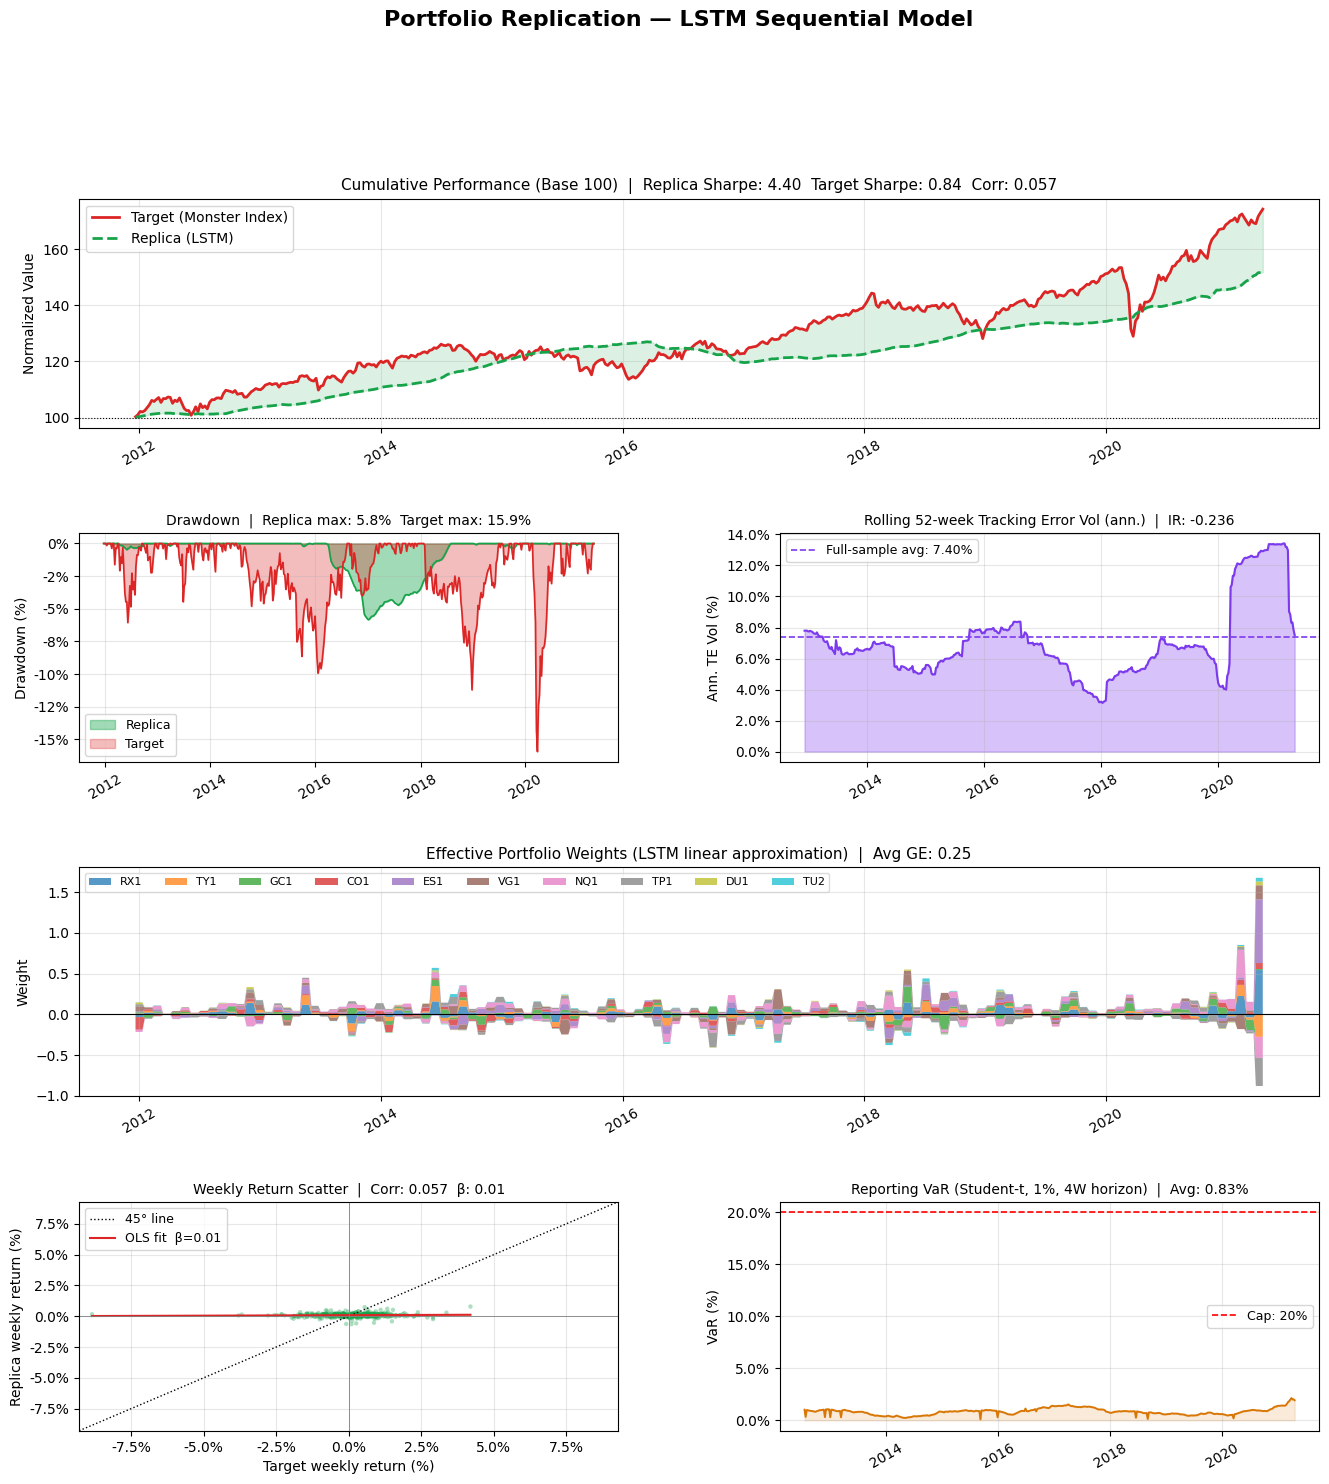

Dashboard saved as lstm_replication_dashboard.png


In [33]:
# ── Dashboard ─────────────────────────────────────────────────────────────────

C_LSTM    = '#16A34A'   # green — distinct from EN (blue) and Kalman (amber)
C_TARGET  = '#DC2626'   # red
C_TE_LSTM = '#7C3AED'   # purple
ALPHA_FILL = 0.15

cum_replica_LSTM_plot = (1 + y_pred_LSTM).cumprod() * 100
cum_target_LSTM_plot  = (1 + y_test_LSTM).cumprod() * 100

roll_te_vol_LSTM = (
    (y_pred_LSTM - y_test_LSTM).rolling(52).std() * np.sqrt(52) * 100
)

weights_LSTM_df = pd.DataFrame(
    np.array(weights_LSTM)[:min_len_lstm],
    index=pd.DatetimeIndex(dates_LSTM[:min_len_lstm]),
    columns=futures_ret.columns
)

fig = plt.figure(figsize=(16, 16))
fig.suptitle(
    'Portfolio Replication — LSTM Sequential Model',
    fontsize=16, fontweight='bold', y=0.998
)

gs   = gridspec.GridSpec(4, 2, figure=fig, hspace=0.46, wspace=0.30)
ax1  = fig.add_subplot(gs[0, :])   # full-width
ax2  = fig.add_subplot(gs[1, 0])
ax3  = fig.add_subplot(gs[1, 1])
ax4  = fig.add_subplot(gs[2, :])
ax5  = fig.add_subplot(gs[3, 0])
ax6  = fig.add_subplot(gs[3, 1])

date_fmt = mdates.DateFormatter('%Y')
date_loc = mdates.YearLocator(2)

# ── Panel 1: Cumulative performance ──────────────────────────────────────────
ax1.plot(cum_target_LSTM_plot.index,  cum_target_LSTM_plot.values,
         color=C_TARGET, lw=2.0, label='Target (Monster Index)')
ax1.plot(cum_replica_LSTM_plot.index, cum_replica_LSTM_plot.values,
         color=C_LSTM,   lw=2.0, linestyle='--', label='Replica (LSTM)')
ax1.fill_between(
    cum_target_LSTM_plot.index,
    cum_target_LSTM_plot.values,
    cum_replica_LSTM_plot.values,
    alpha=ALPHA_FILL, color=C_LSTM
)
ax1.axhline(100, color='black', lw=0.8, linestyle=':')
ax1.set_title(
    f'Cumulative Performance (Base 100)  |  '
    f'Replica Sharpe: {sharpe_replica_LSTM:.2f}  '
    f'Target Sharpe: {sharpe_target_LSTM:.2f}  '
    f'Corr: {corr_LSTM:.3f}',
    fontsize=11
)
ax1.set_ylabel('Normalized Value')
ax1.legend(loc='upper left', fontsize=10)
ax1.xaxis.set_major_formatter(date_fmt)
ax1.xaxis.set_major_locator(date_loc)
ax1.grid(True, alpha=0.3); ax1.tick_params(axis='x', rotation=30)

# ── Panel 2: Drawdown ─────────────────────────────────────────────────────────
ax2.fill_between(dd_replica_LSTM.index, -dd_replica_LSTM.values*100, 0,
                 color=C_LSTM,   alpha=0.4, label='Replica')
ax2.fill_between(dd_target_LSTM.index,  -dd_target_LSTM.values*100,  0,
                 color=C_TARGET, alpha=0.3, label='Target')
ax2.plot(dd_replica_LSTM.index, -dd_replica_LSTM.values*100, color=C_LSTM,   lw=1.2)
ax2.plot(dd_target_LSTM.index,  -dd_target_LSTM.values*100,  color=C_TARGET, lw=1.2)
ax2.set_title(
    f'Drawdown  |  Replica max: {mdd_replica_LSTM*100:.1f}%  '
    f'Target max: {mdd_target_LSTM*100:.1f}%',
    fontsize=10
)
ax2.set_ylabel('Drawdown (%)')
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(date_fmt); ax2.xaxis.set_major_locator(date_loc)
ax2.grid(True, alpha=0.3); ax2.tick_params(axis='x', rotation=30)

# ── Panel 3: Rolling tracking error ──────────────────────────────────────────
ax3.plot(roll_te_vol_LSTM.index, roll_te_vol_LSTM.values, color=C_TE_LSTM, lw=1.5)
ax3.fill_between(roll_te_vol_LSTM.index, roll_te_vol_LSTM.values,
                 alpha=ALPHA_FILL * 2, color=C_TE_LSTM)
ax3.axhline(
    te_vol_LSTM * 100,
    color=C_TE_LSTM, lw=1.2, linestyle='--',
    label=f'Full-sample avg: {te_vol_LSTM*100:.2f}%'
)
ax3.set_title(
    f'Rolling 52-week Tracking Error Vol (ann.)  |  IR: {ir_LSTM:.3f}',
    fontsize=10
)
ax3.set_ylabel('Ann. TE Vol (%)')
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax3.legend(fontsize=9)
ax3.xaxis.set_major_formatter(date_fmt); ax3.xaxis.set_major_locator(date_loc)
ax3.grid(True, alpha=0.3); ax3.tick_params(axis='x', rotation=30)

# ── Panel 4: Effective weights over time ──────────────────────────────────────
pos_w = weights_LSTM_df.clip(lower=0)
neg_w = weights_LSTM_df.clip(upper=0)
colors_w = plt.cm.tab10(np.linspace(0, 1, len(weights_LSTM_df.columns)))

ax4.stackplot(weights_LSTM_df.index, pos_w.T.values,
              labels=weights_LSTM_df.columns.tolist(),
              colors=colors_w, alpha=0.75)
ax4.stackplot(weights_LSTM_df.index, neg_w.T.values,
              colors=colors_w, alpha=0.75)
ax4.axhline(0, color='black', lw=0.8)
ax4.set_title(
    f'Effective Portfolio Weights (LSTM linear approximation)  |  '
    f'Avg GE: {gross_exposure_LSTM.mean():.2f}',
    fontsize=11
)
ax4.set_ylabel('Weight')
ax4.legend(loc='upper left', fontsize=8, ncol=len(weights_LSTM_df.columns),
           bbox_to_anchor=(0, 1.0), framealpha=0.7)
ax4.xaxis.set_major_formatter(date_fmt); ax4.xaxis.set_major_locator(date_loc)
ax4.grid(True, alpha=0.3); ax4.tick_params(axis='x', rotation=30)

# ── Panel 5: Weekly return scatter ────────────────────────────────────────────
ax5.scatter(
    y_test_LSTM.values*100, y_pred_LSTM.values*100,
    alpha=0.35, s=10, color=C_LSTM, edgecolors='none'
)
lim5 = max(abs(y_test_LSTM.values*100).max(), abs(y_pred_LSTM.values*100).max()) * 1.05
ax5.plot([-lim5, lim5], [-lim5, lim5], color='black', lw=1.0, linestyle=':', label='45° line')
m5, b5 = np.polyfit(y_test_LSTM.values, y_pred_LSTM.values, 1)
xf5 = np.linspace(y_test_LSTM.min(), y_test_LSTM.max(), 200)
ax5.plot(xf5*100, (m5*xf5+b5)*100, color=C_TARGET, lw=1.5, label=f'OLS fit  β={m5:.2f}')
ax5.set_xlim(-lim5, lim5); ax5.set_ylim(-lim5, lim5)
ax5.set_xlabel('Target weekly return (%)')
ax5.set_ylabel('Replica weekly return (%)')
ax5.set_title(f'Weekly Return Scatter  |  Corr: {corr_LSTM:.3f}  β: {m5:.2f}', fontsize=10)
ax5.axhline(0, color='grey', lw=0.6); ax5.axvline(0, color='grey', lw=0.6)
ax5.legend(fontsize=9); ax5.grid(True, alpha=0.3)
ax5.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax5.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

# ── Panel 6: VaR over time ────────────────────────────────────────────────────
ax6.plot(var_LSTM.index, var_LSTM.values * 100, color='#D97706', lw=1.4)
ax6.fill_between(var_LSTM.index, var_LSTM.values * 100, alpha=0.15, color='#D97706')
ax6.axhline(LSTM_MAX_VAR * 100, color='red', lw=1.2, linestyle='--',
            label=f'Cap: {LSTM_MAX_VAR:.0%}')
ax6.set_title(f'Reporting VaR (Student-t, 1%, 4W horizon)  |  Avg: {var_LSTM.mean()*100:.2f}%',
              fontsize=10)
ax6.set_ylabel('VaR (%)')
ax6.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax6.legend(fontsize=9)
ax6.xaxis.set_major_formatter(date_fmt); ax6.xaxis.set_major_locator(date_loc)
ax6.grid(True, alpha=0.3); ax6.tick_params(axis='x', rotation=30)

plt.savefig('lstm_replication_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved as lstm_replication_dashboard.png')